# Лабораторна робота № 6
## Конвеєр інтелектуального аналізу даних та інтерпретація моделі

**Інтелектуальний аналіз та візуалізація даних** · 4 години · 4 бали

---

### Постановка

Ви — аналітик інтернет-провайдера. Маркетинг просить модель, яка **в момент
звернення клієнта** оцінює ризик, що той розірве договір протягом кварталу.
Модель потрібна не заради числа: за її підказкою відділ утримання
телефонуватиме людям і пропонуватиме знижку. Тому від вас хочуть **дві речі**:

1. чесну оцінку якості;
2. **пояснення**, чому модель вважає конкретного клієнта ризиковим.

Вам видали вивантаження з CRM. Воно зроблене не для аналізу, а для звітності,
тому в ньому є все підряд — зокрема й те, чого в момент прогнозу ще не існує.

> **Попередження, яке варто прочитати двічі.** Перший результат, який ви
> отримаєте, буде прекрасним. Робота полягає в тому, щоб з'ясувати, чому
> йому не можна вірити, і скільки залишиться після того, як ви приберете
> все зайве.

### Що здаєте

Цей ноутбук із заповненими комірками, виконаними **згори вниз без помилок**,
і відповідями на питання розділу 16.

### Як оцінюється

| Частина | Що оцінюється | Балів |
|---|---|---|
| 1 | Конвеєр: обробка, витік, чесне число, вибір методу | 2,0 |
| 2 | Інтерпретація: важливість, PDP, SHAP | 1,5 |
| 3 | Звіт: обґрунтування рішень і виявлені хибні інтерпретації | 0,5 |

Штраф −0,5 бала, якщо ноутбук не виконується згори вниз на чистому ядрі.

---
## 0. Ваш варіант

Впишіть прізвище та номер у списку групи. Файл даних підтягнеться сам.

In [12]:
STUDENT_NAME = 'Стик Назарій Олегович'     # напр. 'Коваленко Іван Петрович'
LIST_NUMBER  = 17      # номер у списку групи

assert STUDENT_NAME and LIST_NUMBER > 0, 'впишіть прізвище та номер у списку'
VARIANT = (LIST_NUMBER - 1) % 30 + 1
DATA = 'lr6_варіант_%02d.csv' % VARIANT
print('варіант %d, файл %s' % (VARIANT, DATA))

варіант 17, файл lr6_варіант_17.csv


> Файли варіантів лежать у теці `дані/` поряд із ноутбуком. Якщо викладач
> призначив вам інший варіант — перепишіть `VARIANT` вручну і зазначте це у звіті.

In [13]:
import importlib.util, subprocess, sys
REQUIRED = ['pandas', 'numpy', 'scikit-learn', 'matplotlib', 'shap']
MODNAME  = {'scikit-learn': 'sklearn'}
missing = [p for p in REQUIRED if importlib.util.find_spec(MODNAME.get(p, p)) is None]
if missing:
    print('встановлюю:', ', '.join(missing), '...')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print('усі пакети на місці')

усі пакети на місці


In [14]:
import warnings; warnings.filterwarnings('ignore')
import os, re, json, time, datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import (RepeatedStratifiedKFold, cross_val_score,
                                     train_test_split)
from sklearn.inspection import permutation_importance, partial_dependence
from sklearn.metrics import roc_auc_score, confusion_matrix, classification_report

SEED = 42
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 60)
print('усе імпортовано')

усе імпортовано


---
## 1. Три рішення, які ухвалюють ДО того, як торкнутись даних

Нагадування з лекції 7: кроки 1–3 алгоритму виконуються перш ніж
ви напишете хоч один рядок обробки. Якщо обрати метрику після того, як
побачив результати, ви оберете ту, яка показала більше.

### Завдання 1.1

Заповніть три змінні нижче і **обґрунтуйте кожну** одним реченням у коментарі.

In [15]:
# ----- ВАШІ ВІДПОВІДІ -----

TYPE_OF_TASK = 'класифікація'
# чому: ціль "відтік" бінарна (1 - пішов, 0 - лишився), треба віднести клієнта до одного з двох класів.

METRIC = 'AUC'
# чому саме ця, а не точність: відтоку 25,75 %, тож модель "ніхто не піде" має точність 74,25 % при нульовій користі;
# AUC не залежить від дисбалансу і порогу і оцінює саме ранжування клієнтів за ризиком, яке потрібне відділу утримання.

CV_SCHEME = 'стратифікована 5-кратна, 4 повтори'
# чому саме така: стратифікація зберігає частку відтоку в кожній згортці, а 4 повтори дають 20 оцінок,
# щоб бачити не одне випадкове число, а середнє і розкид (на 1200 рядках одна згортка дуже шумна).

for nme, val in [('TYPE_OF_TASK', TYPE_OF_TASK), ('METRIC', METRIC), ('CV_SCHEME', CV_SCHEME)]:
    assert val, 'не заповнено: ' + nme
print('рішення зафіксовані')

рішення зафіксовані


> **Підказка до METRIC.** Подивіться на частку відтоку в наступному розділі.
> Якщо вона далека від 50 %, подумайте, яку точність дасть модель
> «ніхто не піде» — і чи варта вона чогось.

---
## 2. Перший погляд на дані

### Завдання 2.1

Прочитайте файл і дайте відповідь на чотири питання: скільки рядків і стовпців,
яка частка відтоку, скільки стовпців має невизначений тип, де найбільше пропусків.

In [16]:
raw = pd.read_csv(os.path.join('дані', DATA), encoding='utf-8-sig')
TARGET = 'відтік'

print('розмір:', raw.shape)
print('частка відтоку: %.3f' % raw[TARGET].mean())
print()
print('типи стовпців:', raw.dtypes.astype(str).value_counts().to_dict())

розмір: (1200, 26)
частка відтоку: 0.258

типи стовпців: {'str': 14, 'float64': 6, 'int64': 6}


In [17]:
# ----- ВАШ КОД: таблиця «стовпець | тип | унікальних | % пропусків | приклад» -----
# Відсортуйте за часткою пропусків спадно і покажіть усі стовпці.

info = pd.DataFrame({
    'тип':         raw.dtypes.astype(str),             # який тип pandas призначив стовпцю
    'унікальних':  raw.nunique(),                      # скільки різних значень (NaN не рахується)
    '% пропусків': (raw.isna().mean() * 100).round(1), # частка NaN у відсотках
    'приклад':     [raw[c].dropna().iloc[0] if raw[c].notna().any() else None
                    for c in raw.columns],             # перше непорожнє значення
})
info.index.name = 'стовпець'
info = info.sort_values('% пропусків', ascending=False)
display(info)

,тип,унікальних,% пропусків,приклад
стовпець,,,,
дата_розірвання,str,261,74.2,2023-11-24
код_причини_закриття,str,5,74.2,ЯКІ-03
середній_час_відповіді_хв,float64,272,33.3,14.2
трафік_ГБ,str,959,5.0,154.4
щомісячний_платіж,str,1122,4.0,263.55
аварій_на_ділянці_за_квартал,float64,7,3.0,0.0
стать,str,6,0.0,чол
місто,str,6,0.0,Стрий
id_клієнта,str,1200,0.0,K170000


**Висновок до 2.1.**
- Розмір: 1200 рядків, 26 стовпців.
- Частка відтоку: 0,2575 (309 клієнтів), класи незбалансовані.
- Невизначений (текстовий) тип `str` мають 14 стовпців. Більшість із них - справжні категорії (стать, місто, тариф, філія), але `трафік_ГБ` і `щомісячний_платіж` за змістом числові, тобто містять текстові значення.
- Найбільше пропусків: `дата_розірвання` і `код_причини_закриття` - по 74,2 %, що збігається з часткою клієнтів, які лишились (74,25 %), тобто ці поля заповнені лише для тих, хто пішов (кандидати на цільовий витік). Далі - `середній_час_відповіді_хв` (33,3 %).
- `стать` має 6 унікальних значень замість 2 (неохайний запис), `id_клієнта` та `індекс_лояльності_CRM` - по 1200 унікальних значень.

### Завдання 2.2 — три способи, якими дані вже зіпсовані

У вивантаженні є щонайменше три проблеми, кожна з яких тихо зламає модель.
Знайдіть їх і **назвіть конкретні стовпці**.

1. Числова колонка, у якій частина значень записана **текстом**.
2. Колонка, у якій Excel перетворив число на **дату**.
3. Колонка, пропуски в якій **не випадкові** — їхня наявність сама щось означає
   (механізм MNAR за класифікацією Рубіна, розділ 7.2 конспекту).

In [18]:
# ----- ВАШ КОД: знайдіть і покажіть по кілька прикладів кожної проблеми -----

# 1) текст у числовій колонці: значення, які не перетворюються на число
for c in ['щомісячний_платіж', 'трафік_ГБ']:
    s = raw[c].dropna()
    bad = s[pd.to_numeric(s, errors='coerce').isna()]   # що не стало числом
    print('%s: %d нечислових значень, приклади: %s' % (c, len(bad), bad.head(5).tolist()))

# 2) Excel-дата: значення, схожі на дату 1900-го року
s = raw['трафік_ГБ'].dropna().astype(str)
print('\nтрафік_ГБ, схожі на дату:', s[s.str.startswith('1900-')].tolist())

# 3) MNAR: де пропущений час відповіді і скільки звернень у цих людей
print('\nпропуск часу відповіді  x  кількість звернень:')
display(pd.crosstab(raw['середній_час_відповіді_хв'].isna(),
                    raw['кількість_звернень_у_підтримку']))

щомісячний_платіж: 26 нечислових значень, приклади: ['440.57 грн', '257.76 грн', '347.39 грн', '252.21 грн', '221.09 грн']
трафік_ГБ: 3 нечислових значень, приклади: ['1900-01-08 00:00:00', '1900-01-02 00:00:00', '1900-01-26 00:00:00']

трафік_ГБ, схожі на дату: ['1900-01-08 00:00:00', '1900-01-02 00:00:00', '1900-01-26 00:00:00']

пропуск часу відповіді  x  кількість звернень:


кількість_звернень_у_підтримку,0,1,2,3,4,5,6
середній_час_відповіді_хв,,,,,,,
False,0,437,256,76,22,7,2
True,400,0,0,0,0,0,0


In [19]:
PROBLEM_TEXT_IN_NUMBER = 'щомісячний_платіж'    # назва стовпця
PROBLEM_EXCEL_DATE     = 'трафік_ГБ'    # назва стовпця
PROBLEM_MNAR           = 'середній_час_відповіді_хв'    # назва стовпця
MNAR_MEANING           = 'пропуск означає, що клієнт жодного разу не звертався в підтримку'    # що означає сам факт пропуску, одним реченням

for nme, val in [('PROBLEM_TEXT_IN_NUMBER', PROBLEM_TEXT_IN_NUMBER),
                 ('PROBLEM_EXCEL_DATE', PROBLEM_EXCEL_DATE),
                 ('PROBLEM_MNAR', PROBLEM_MNAR), ('MNAR_MEANING', MNAR_MEANING)]:
    assert val, 'не заповнено: ' + nme
assert PROBLEM_TEXT_IN_NUMBER in raw.columns and PROBLEM_EXCEL_DATE in raw.columns
assert PROBLEM_MNAR in raw.columns
print('проблеми названо')

проблеми названо


**Висновок до 2.2.** `щомісячний_платіж` - 26 значень текстом із "грн" (`'440.57 грн'`); `трафік_ГБ` - 3 значення, які Excel перетворив на дати `1900-01-xx` (брак, стане NaN); `середній_час_відповіді_хв` - MNAR: усі 400 пропусків рівно в клієнтів із 0 звернень у підтримку, тобто пропуск означає "не звертався".

---
## 3. Будуємо матрицю ознак

Перетворення сирої таблиці на матрицю `X` — це фаза 3 CRISP-DM. Усі рішення
тут приймаються **явно** і записуються, бо потім їх доведеться захищати.

### Завдання 3.1

Допишіть `to_number` і `build_X`.

* `to_number` має витягати число з тексту `'350.5 грн'`, **не** перетворювати
  дату на число і повертати `NaN` там, де числа немає.
* `build_X` для кожного стовпця вирішує: число, категорія чи викинути.
  Дата підключення має стати **числом** (напр. порядковим номером дня) —
  інакше модель її не з'їсть.

In [20]:
def to_number(s):
    """Витягує число з колонки, де перемішані числа, текст і дати."""
    def one(v):
        # 1) None / NaN -> np.nan
        if v is None or (isinstance(v, float) and np.isnan(v)):
            return np.nan
        # 2) datetime / Timestamp -> np.nan (це брак, а не дані)
        if isinstance(v, (datetime.date, datetime.datetime)):
            return np.nan
        # 3) число -> float
        if isinstance(v, (int, float, np.integer, np.floating)) and not isinstance(v, bool):
            return float(v)
        # 4) текст
        t = str(v).strip()
        if re.match(r'^\d{4}-\d{2}-\d{2}', t):        # дата, записана текстом ('1900-01-08 00:00:00')
            return np.nan
        m = re.match(r'^-?\d+(?:[.,]\d+)?', t)         # число на початку: '350.5 грн', '2,75'
        return float(m.group().replace(',', '.')) if m else np.nan
    return s.map(one)


# самоперевірка
_t = pd.Series([1, '350.5 грн', '2,75', datetime.datetime(1900, 1, 11), None, 'немає'])
_r = to_number(_t)
assert _r[0] == 1.0 and abs(_r[1] - 350.5) < 1e-9 and abs(_r[2] - 2.75) < 1e-9
assert np.isnan(_r[3]), 'дата має стати NaN, а не числом'
assert np.isnan(_r[4]) and np.isnan(_r[5])
print('to_number працює')

to_number працює


In [21]:
DROP_ALWAYS = ['id_клієнта']   # ідентифікатор: нічого не пояснює, лише запам'ятовується

def build_X(d, drop):
    """Сира таблиця -> матриця ознак. Категорії лишаємо типом category."""
    X = pd.DataFrame(index=d.index)
    log = []
    for c in d.columns:
        if c in drop or c == TARGET:
            continue
        s = d[c]
        if c.startswith('дата_'):
            # дата -> кількість днів від 2000-01-01
            dt = pd.to_datetime(s, errors='coerce')
            X[c] = (dt - pd.Timestamp('2000-01-01')).dt.days.astype(float)
            how = 'дата -> днів від 2000-01-01'
        elif pd.api.types.is_numeric_dtype(s):
            # уже число
            X[c] = s.astype(float)
            how = 'число'
        else:
            # текст: пробуємо витягти числа
            num = to_number(s)
            share = num.notna().sum() / max(s.notna().sum(), 1)
            if share > 0.8:
                X[c] = num.astype(float)
                how = 'текст -> число (розібрано %.1f%%)' % (share * 100)
            else:
                # категорія: прибрати пробіли, нижній регістр
                t = s.map(lambda v: v if pd.isna(v) else str(v).strip().lower())
                if c == 'стать':                 # ч/чол -> ч, ж/жін -> ж
                    t = t.map(lambda v: v if pd.isna(v) else v[0])
                X[c] = t.astype(object).astype('category')
                how = 'категорія (%d рівнів)' % X[c].nunique()
        log.append({'стовпець': c, 'рішення': how, 'пропусків': int(X[c].isna().sum())})
    return X, pd.DataFrame(log)


X_all, log = build_X(raw, DROP_ALWAYS)
y = raw[TARGET].astype(int)
print('матриця ознак:', X_all.shape)
print('категоріальних:', sum(str(X_all[c].dtype) == 'category' for c in X_all.columns))
display(log)

матриця ознак: (1200, 24)
категоріальних: 9


,стовпець,рішення,пропусків
0,вік,число,0
1,стать,категорія (2 рівнів),0
2,місто,категорія (6 рівнів),0
3,філія,категорія (6 рівнів),0
4,тариф,категорія (4 рівнів),0
5,тип_підключення,категорія (3 рівнів),0
6,спосіб_оплати,категорія (3 рівнів),0
7,автоплатіж,категорія (2 рівнів),0
8,кількість_послуг,число,0
9,місяців_обслуговування,число,0


**Висновок до 3.1.** `to_number` витягує число з тексту ('350.5 грн' -> 350.5, '2,75' -> 2.75), а дати (і об'єкти, і текст вигляду 1900-01-08) перетворює на NaN як брак. `build_X` дає матрицю 1200 x 24: дати -> дні від 2000-01-01; `щомісячний_платіж` і `трафік_ГБ` -> числа (3 Excel-дати в трафіку стали NaN); 9 категоріальних ознак приведено до нижнього регістру, `стать` зведено з 6 записів до 2 (ч/ж).

### Завдання 3.2 — конвеєр

Зберіть `make_pipe(X, clf)`: колонковий перетворювач (числові — медіана плюс
стандартизація; категоріальні — мода плюс одиничне кодування) і модель.

> **Чому саме так.** Відповідь у розділі 10 конспекту: усе, що має `fit`,
> мусить опинитись **усередині** конвеєра, інакше крос-валідація бреше.
> Зверніть увагу на `handle_unknown='ignore'` — без нього модель упаде на
> категорії, якої не було в навчальній згортці.

In [22]:
def make_pipe(X, clf):
    # які стовпці категоріальні, а які числові - визначаємо за типом
    cat = [c for c in X.columns if str(X[c].dtype) == 'category']
    num = [c for c in X.columns if c not in cat]

    prep = ColumnTransformer([
        # числові: пропуски -> медіана, далі стандартизація
        ('num', Pipeline([('imp',   SimpleImputer(strategy='median')),
                          ('scale', StandardScaler())]), num),
        # категоріальні: пропуски -> найчастіше значення, далі one-hot
        ('cat', Pipeline([('imp',    SimpleImputer(strategy='most_frequent')),
                          ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cat),
    ])
    # обробка + модель = один оцінювач
    return Pipeline([('prep', prep), ('clf', clf)])


def logreg():
    return LogisticRegression(max_iter=3000, random_state=SEED)


cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=4, random_state=SEED)

# самоперевірка: конвеєр має бути єдиним оцінювачем і переживати крос-валідацію
_p = make_pipe(X_all, logreg())
assert hasattr(_p, 'fit') and hasattr(_p, 'predict')
_s = cross_val_score(_p, X_all, y, cv=RepeatedStratifiedKFold(
    n_splits=5, n_repeats=1, random_state=SEED), scoring='roc_auc')
assert len(_s) == 5
print('конвеєр зібрано, пробний прогін AUC %.3f' % _s.mean())

конвеєр зібрано, пробний прогін AUC 0.975


**Висновок до 3.2.** Обробку (медіана + стандартизація для чисел, мода + one-hot для категорій) і модель зібрано в один Pipeline, тому під час крос-валідації всі `fit` виконуються лише на навчальній згортці (немає препроцесингового витоку); `handle_unknown='ignore'` захищає від нових категорій у тестовій згортці. Пробний прогін: AUC 0,975, що підозріло високо.

---
## 4. Перший результат

Запустіть модель на **всьому, що є**, — саме так робить дев'ять аналітиків
із десяти, коли їм дали вивантаження і попросили «подивитись, чи взагалі
щось передбачається».

In [23]:
t0 = time.time()
auc_naive = cross_val_score(make_pipe(X_all, logreg()), X_all, y, cv=cv, scoring='roc_auc')
print('ознак    : %d' % X_all.shape[1])
print('AUC      : %.3f ± %.3f' % (auc_naive.mean(), auc_naive.std()))
print('час      : %.1f c' % (time.time() - t0))

ознак    : 24
AUC      : 0.975 ± 0.011
час      : 0.7 c


### Завдання 4.1

Подивіться на число і на таблицю орієнтирів AUC з розділу 4.4 конспекту.

Запишіть у `FIRST_REACTION` одне речення: що саме це число означає
і яка з двох причин високої AUC, найімовірніше, спрацювала.

In [24]:
FIRST_REACTION = ('AUC 0,975 ± 0,011 означає, що в 97,5 % пар "пішов - лишився" модель ставить вищий ризик тому, хто пішов; '
                  'для відтоку це нереально високо (вище 0,95 - ознака витоку), тож найімовірніше спрацював витік: '
                  'у моделі є поля, записані вже після розірвання, наприклад дата_розірвання і код_причини_закриття, '
                  'які заповнені лише в тих, хто пішов.')
assert FIRST_REACTION, 'напишіть, що ви думаєте про це число'
print(FIRST_REACTION)

AUC 0,975 ± 0,011 означає, що в 97,5 % пар "пішов - лишився" модель ставить вищий ризик тому, хто пішов; для відтоку це нереально високо (вище 0,95 - ознака витоку), тож найімовірніше спрацював витік: у моделі є поля, записані вже після розірвання, наприклад дата_розірвання і код_причини_закриття, які заповнені лише в тих, хто пішов.


**Висновок до 4.1.** На всіх 24 ознаках AUC = 0,975 ± 0,011. Це вище порогу 0,95, за яким на реальних даних майже завжди стоїть витік, а не добра модель: серед ознак є поля, які існують лише після розірвання договору.

---
## 5. Шукаємо витік

Чотири типи витоку (розділ 9.1 конспекту) і засіб проти кожного:

| Тип | Засіб |
|---|---|
| цільовий | чек-ліст: чи існує значення в момент прогнозу |
| препроцесинговий | конвеєр |
| часовий | часова схема перевірки |
| груповий | групова схема перевірки |

Починаємо з цільового.

### Завдання 5.1 — автоматичний детектор

Напишіть `leak_scan`: для кожного стовпця перевірте, чи **сам факт
заповненості** передбачає клас. Поріг `min_group` обов'язковий — без нього
детектор видає хибні спрацювання на колонках, заповнених у двох клієнтів.

In [25]:
def leak_scan(d, y, min_group=20):
    """Для кожного стовпця: наскільки добре його заповненість вгадує клас.

    Повертає таблицю зі стовпцями: ознака, заповнено, частка_відтоку_де_заповнено,
    частка_відтоку_де_пропуск, показник (0.5 = нічого, 1.0 = ідеальний поділ).
    """
    rows = []
    for c in d.columns:
        if c == TARGET:
            continue
        filled = d[c].notna()                      # True там, де значення є
        n_filled, n_missing = int(filled.sum()), int((~filled).sum())

        churn_f = y[filled].mean() if n_filled else np.nan     # відтік серед заповнених
        churn_m = y[~filled].mean() if n_missing else np.nan   # відтік серед пропусків

        if n_filled >= min_group and n_missing >= min_group:
            score = roc_auc_score(y, filled.astype(int))
            score = max(score, 1 - score)          # "навпаки" теж ідеальний поділ
        else:
            score = np.nan                         # замала група, не рахуємо

        rows.append({'ознака': c, 'заповнено': n_filled,
                     'частка_відтоку_де_заповнено': round(churn_f, 3),
                     'частка_відтоку_де_пропуск': round(churn_m, 3),
                     'показник': round(score, 3)})
    return pd.DataFrame(rows).sort_values('показник', ascending=False)


scan = leak_scan(raw, y)
display(scan.head(10))

,ознака,заповнено,частка_відтоку_де_заповнено,частка_відтоку_де_пропуск,показник
22,код_причини_закриття,309,1.000,0.000,1.000
23,дата_розірвання,309,1.000,0.000,1.000
17,середній_час_відповіді_хв,800,0.275,0.222,0.531
14,трафік_ГБ,1140,0.259,0.233,0.503
16,аварій_на_ділянці_за_квартал,1164,0.257,0.278,0.502
12,щомісячний_платіж,1152,0.258,0.250,0.501
0,id_клієнта,1200,0.258,NaN,NaN
1,вік,1200,0.258,NaN,NaN
2,стать,1200,0.258,NaN,NaN
3,місто,1200,0.258,NaN,NaN


**Висновок до 5.1.** Детектор рахує AUC заповненості стовпця щодо цілі (з порогом 20 спостережень на кожну групу). Показник 1,0 мають `код_причини_закриття` і `дата_розірвання`: обидва заповнені рівно в 309 клієнтів, які пішли, і порожні в усіх, хто лишився. Решта стовпців із пропусками мають показник 0,50-0,53, тобто їхня заповненість класу не видає.

### Завдання 5.2 — цільовий витік

Стовпці з показником близько 1,0 заповнені **лише в одного класу**. Такий
стовпець записаний уже після того, як результат став відомий.

Випишіть їх у `TARGET_LEAK` і **для кожного поясніть одним реченням**, чому
його не існує в момент прогнозу.

In [26]:
TARGET_LEAK = [
    'дата_розірвання',        # записується в день розірвання договору; у момент дзвінка договір ще чинний, дати не існує
    'код_причини_закриття',   # менеджер вписує причину лише під час оформлення закриття, тобто вже після відтоку
]
assert len(TARGET_LEAK) >= 2, 'таких стовпців більше ніж один'
assert all(c in raw.columns for c in TARGET_LEAK)
print('цільовий витік:', TARGET_LEAK)

цільовий витік: ['дата_розірвання', 'код_причини_закриття']


In [27]:
X2, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK)
auc2 = cross_val_score(make_pipe(X2, logreg()), X2, y, cv=cv, scoring='roc_auc')
print('після вилучення цільового витоку: %d ознак, AUC %.3f ± %.3f'
      % (X2.shape[1], auc2.mean(), auc2.std()))

після вилучення цільового витоку: 22 ознак, AUC 0.909 ± 0.013


**Висновок до 5.2.** Цільовий витік - `дата_розірвання` і `код_причини_закриття`: обидва з'являються лише в момент оформлення розірвання, тобто після події, яку ми прогнозуємо. Після їх вилучення AUC впала з 0,975 до 0,909 ± 0,013, але для відтоку це досі підозріло високо: детектор знаходить лише стовпці, у яких витік видно через пропуски.

### Завдання 5.3 — витік, якого детектор НЕ бачить

Число майже не впало. Отже головне ще попереду.

Детектор знаходить колонки, **формально** пов'язані з ціллю. Він безсилий
проти колонки, яка формально бездоганна, але якої **не існує в момент,
коли ухвалюється рішення** — або яка означає не те, що здається.

Перегляньте решту стовпців **очима** і поставте кожному питання з розділу 9.3:

> **Чи міг я знати це значення в ту мить, коли треба ухвалити рішення?**

Нагадування про момент прогнозу: клієнт щойно зателефонував, договір
**чинний**, рішення про знижку ухвалюється **зараз**.

In [28]:
# ----- ВАШ КОД: перегляньте список стовпців, що лишились -----
print(list(X2.columns))

# підозрюваний: дзвінки відділу утримання
print('\nвідтік за кількістю дзвінків утримання:')
display(pd.crosstab(raw['кількість_дзвінків_утримання'], y, margins=True))
print(raw.groupby(raw['кількість_дзвінків_утримання'] > 0)[TARGET].agg(['mean', 'size'])
         .rename(index={False: '0 дзвінків', True: '1+ дзвінків'}))

['вік', 'стать', 'місто', 'філія', 'тариф', 'тип_підключення', 'спосіб_оплати', 'автоплатіж', 'кількість_послуг', 'місяців_обслуговування', 'швидкість_тарифу_Мбіт', 'щомісячний_платіж', 'знижка_відсоток', 'трафік_ГБ', 'кількість_звернень_у_підтримку', 'аварій_на_ділянці_за_квартал', 'середній_час_відповіді_хв', 'річний_платіж', 'номер_договору_серія', 'індекс_лояльності_CRM', 'дата_підключення', 'кількість_дзвінків_утримання']

відтік за кількістю дзвінків утримання:


відтік,0,1,All
кількість_дзвінків_утримання,,,
0,783,60,843
1,20,55,75
2,19,49,68
3,18,48,66
4,33,44,77
5,18,53,71
All,891,309,1200


                                  mean  size
кількість_дзвінків_утримання                
0 дзвінків                    0.071174   843
1+ дзвінків                   0.697479   357


In [29]:
HUMAN_LEAK = [
    'кількість_дзвінків_утримання',   # заповнює відділ утримання, коли клієнт уже заявив про розірвання, тобто після рішення піти
]
HUMAN_LEAK_WHY = ('стовпець не має пропусків (відсутність дзвінків записана як 0, а не NaN), '
                  'тому детектор заповненості не бачить різниці між групами; формально це звичайне число, '
                  'а витік видно лише з питання "хто і коли його заповнює"')

assert len(HUMAN_LEAK) >= 1 and HUMAN_LEAK_WHY
assert all(c in raw.columns for c in HUMAN_LEAK)
X3, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK + HUMAN_LEAK)
auc3 = cross_val_score(make_pipe(X3, logreg()), X3, y, cv=cv, scoring='roc_auc')
print('після вилучення оцінок людини: %d ознак, AUC %.3f ± %.3f'
      % (X3.shape[1], auc3.mean(), auc3.std()))

після вилучення оцінок людини: 21 ознак, AUC 0.819 ± 0.019


**Висновок до 5.3.** Прихований витік - `кількість_дзвінків_утримання`: його заповнює відділ утримання вже після того, як клієнт заявив про намір піти (0 дзвінків - відтік 7 %, 1+ дзвінків - 70 %). Детектор його не бачить, бо пропусків немає (відсутність дзвінків = 0). Після вилучення AUC впала з 0,909 до 0,819 ± 0,019; вилучення інших підозрілих стовпців (індекс_лояльності_CRM, номер_договору_серія, річний_платіж) AUC не змінює.

> Якщо тут число впало **суттєво** — ви знайшли головне. Якщо ні —
> перечитайте список стовпців ще раз: щось лишилось.

---
## 6. Артефакт збору даних

Лишилась найтонша перевірка. Якщо дані про два класи **збиралися
по-різному** — у різні періоди, різними людьми, за різними правилами —
модель вивчає спосіб запису, а не предмет. Жодна окрема колонка при цьому
не є витоком; витоком є вся таблиця.

Обчислювана перевірка з розділу 9.3: спробувати передбачити **не ціль,
а джерело**. Якщо за тими самими чесними ознаками добре вгадується філія
або період підключення — класи не порівнянні між собою.

### Завдання 6.1 — частка відтоку за філіями і за періодом

,частка_відтоку,клієнтів
філія,,
Ф-01 Центр,0.307,215
Ф-02 Захід,0.231,199
Ф-03 Схід,0.238,206
Ф-04 Південь,0.251,203
Ф-05 Північ,0.249,177
Ф-06 Приміська,0.265,200


,частка_відтоку,клієнтів
дата_підключення,,
2023Q1,0.157,140
2023Q2,0.187,150
2023Q3,0.156,160
2023Q4,0.181,149
2024Q1,0.236,140
2024Q2,0.343,137
2024Q3,0.394,155
2024Q4,0.391,169


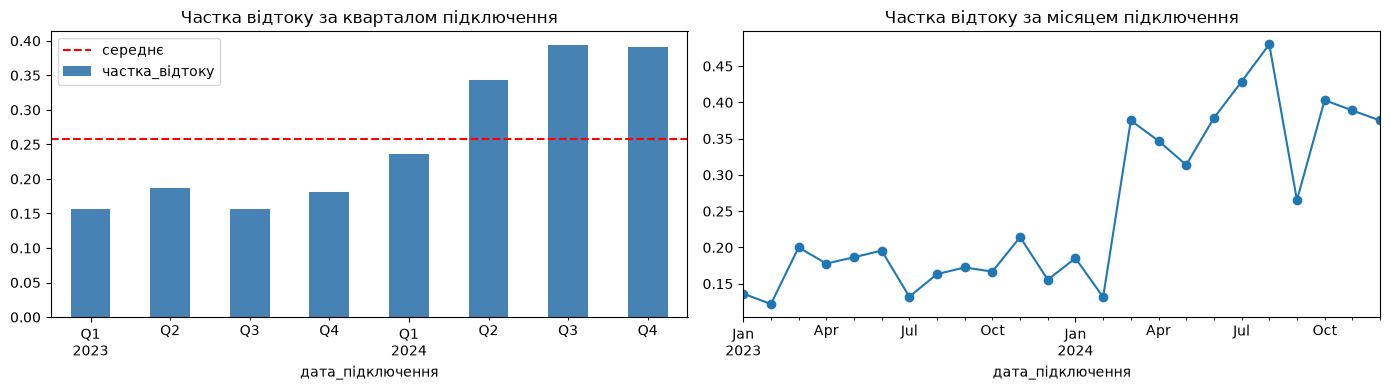

In [30]:
# ----- ВАШ КОД -----
# 1) частка відтоку за філіями
by_branch = raw.groupby('філія')[TARGET].agg(частка_відтоку='mean', клієнтів='size').round(3)
display(by_branch)

# 2) частка відтоку за кварталами дати підключення
conn = pd.to_datetime(raw['дата_підключення'])
by_q = raw.groupby(conn.dt.to_period('Q'))[TARGET].agg(частка_відтоку='mean', клієнтів='size').round(3)
display(by_q)

# 3) по місяцях - щоб точно побачити, де сходинка
by_m = raw.groupby(conn.dt.to_period('M'))[TARGET].mean()

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
by_q['частка_відтоку'].plot(kind='bar', ax=ax[0], color='steelblue')
ax[0].axhline(raw[TARGET].mean(), color='red', ls='--', label='середнє')
ax[0].set_title('Частка відтоку за кварталом підключення'); ax[0].legend()
by_m.plot(ax=ax[1], marker='o')
ax[1].set_title('Частка відтоку за місяцем підключення')
plt.tight_layout(); plt.show()

**Висновок до 6.1.** За філіями частка відтоку рівна (0,23-0,31), сходинки немає. За датою підключення є різка сходинка: до 01.03.2024 відтік стабільно 16-19 % по кварталах (разом 16,9 %), з березня 2024 - 34-39 % (разом 37,7 %). Це не плавна зміна, а стрибок за один місяць, тобто ймовірна зміна правила обліку. Підозрюваний артефакт - `дата_підключення`, дата зламу 2024-03-01.

### Завдання 6.2 — передбачити джерело

Візьміть **ті самі чесні ознаки**, що й для моделі відтоку, і спробуйте
передбачити ними не `відтік`, а ознаку джерела: «клієнт із філії-підозрюваної»
або «підключений після дати-зламу».

Якщо AUC помітно вища за 0,5 — у ваших даних закодоване джерело.

In [31]:
SUSPECT = 'дата_підключення'
assert SUSPECT in ('філія', 'дата_підключення')

# ----- ВАШ КОД: побудуйте бінарну змінну source -----
# 1 - клієнт підключений після дати-зламу (01.03.2024), 0 - до
BREAK_DATE = '2024-03-01'
source = (pd.to_datetime(raw['дата_підключення']) >= BREAK_DATE).astype(int)
print('після зламу: %d клієнтів (%.1f %%)' % (source.sum(), source.mean() * 100))

X4, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK + HUMAN_LEAK + [SUSPECT])
auc_src = cross_val_score(make_pipe(X4, logreg()), X4, source, cv=cv, scoring='roc_auc')
auc4 = cross_val_score(make_pipe(X4, logreg()), X4, y, cv=cv, scoring='roc_auc')
print('ті самі ознаки передбачають ДЖЕРЕЛО : AUC %.3f' % auc_src.mean())
print('ті самі ознаки передбачають ВІДТІК  : AUC %.3f ± %.3f' % (auc4.mean(), auc4.std()))

після зламу: 509 клієнтів (42.4 %)
ті самі ознаки передбачають ДЖЕРЕЛО : AUC 0.805
ті самі ознаки передбачають ВІДТІК  : AUC 0.793 ± 0.022


**Висновок до 6.2.** Джерело - `source = 1` для 509 клієнтів (42,4 %), підключених після 01.03.2024. Чесні ознаки без дати передбачають джерело з AUC 0,805, тобто період "просочується" через інші ознаки: після зламу з'явились швидкості 400/800 Мбіт, більше оптики (85 % проти 68 %) і автоплатежу (63 % проти 43 %). Класи з різних періодів не цілком порівнянні. Відтік без підозрюваного стовпця: AUC 0,793 ± 0,022.

### Завдання 6.3 — драбина

Зведіть усі чотири числа в одну таблицю і подивіться, **де саме** впало.

In [32]:
ladder = pd.DataFrame([
    {'крок': '1. усе підряд',               'ознак': X_all.shape[1], 'AUC': auc_naive.mean()},
    {'крок': '2. мінус цільовий витік',     'ознак': X2.shape[1],    'AUC': auc2.mean()},
    {'крок': '3. мінус оцінки людини',      'ознак': X3.shape[1],    'AUC': auc3.mean()},
    {'крок': '4. мінус артефакт збору',     'ознак': X4.shape[1],    'AUC': auc4.mean()},
]).set_index('крок').round(3)
display(ladder)

HONEST_AUC = float(auc4.mean())
print('чесне число: %.3f ± %.3f' % (HONEST_AUC, auc4.std()))

,ознак,AUC
крок,,
1. усе підряд,24,0.975
2. мінус цільовий витік,22,0.909
3. мінус оцінки людини,21,0.819
4. мінус артефакт збору,20,0.793


чесне число: 0.793 ± 0.022


**Висновок до 6.3.** Драбина AUC: 0,975 (усе) → 0,909 (мінус цільовий витік) → 0,819 (мінус оцінка людини) → 0,793 (мінус артефакт збору). Найбільше падіння (-0,090) дав витік, якого детектор не бачить. Разом витоки завищували AUC на 0,18. Чесне число: 0,793 ± 0,022.

### Завдання 6.4

Чи **правильно** викидати підозрюваний стовпець? Це не риторичне питання:
філія або дата підключення цілком можуть нести справжній сигнал
(щільна забудова, нові тарифи), а не лише артефакт.

Запишіть своє рішення і аргумент. Обидві відповіді приймаються — оцінюється
аргумент, а не вибір.

In [33]:
DECISION_ARTEFACT = 'викинути'
DECISION_WHY = ('частка відтоку стрибає з 13 % (лютий 2024) до 38 % (березень 2024) за один місяць і далі тримається на новому рівні - '
                'це сходинка, тобто зміна правила обліку, а не реальна причина відтоку; модель має працювати на нових клієнтах, '
                'тому вчити її розпізнавати період запису не можна; втрата від вилучення мала (AUC 0,819 -> 0,793, приблизно один розкид). '
                'Застереження: період частково видно і через інші ознаки (AUC джерела 0,805: нові швидкості 400/800 Мбіт, більше оптики й автоплатежу), '
                'тож оцінку якості варто окремо перевірити на клієнтах після 01.03.2024.')
assert DECISION_ARTEFACT and DECISION_WHY
print(DECISION_ARTEFACT, '-', DECISION_WHY)

викинути - частка відтоку стрибає з 13 % (лютий 2024) до 38 % (березень 2024) за один місяць і далі тримається на новому рівні - це сходинка, тобто зміна правила обліку, а не реальна причина відтоку; модель має працювати на нових клієнтах, тому вчити її розпізнавати період запису не можна; втрата від вилучення мала (AUC 0,819 -> 0,793, приблизно один розкид). Застереження: період частково видно і через інші ознаки (AUC джерела 0,805: нові швидкості 400/800 Мбіт, більше оптики й автоплатежу), тож оцінку якості варто окремо перевірити на клієнтах після 01.03.2024.


---
## 7. Крок 4 алгоритму: який метод узяти

Тепер, коли набір ознак чесний, можна обирати модель. Критеріїв чотири
(розділ 6 конспекту), і всі чотири вимірюються.

### Завдання 7.1

Порівняйте щонайменше чотири моделі **на тому самому наборі й тій самій
схемі перевірки**. Для кожної запишіть AUC, розкид і час на 100 навчань.

In [35]:
from sklearn.tree import DecisionTreeClassifier

MODELS = {
    'логістична регресія':  logreg(),
    'одне дерево':          DecisionTreeClassifier(max_depth=5, min_samples_leaf=20, random_state=SEED),
    'випадковий ліс':       RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
    'гістограмний бустинг': HistGradientBoostingClassifier(random_state=SEED),
}

rows = []
for name, clf in MODELS.items():
    assert clf is not None, 'заповніть модель: ' + name
    t0 = time.time()
    a = cross_val_score(make_pipe(X4, clf), X4, y, cv=cv, scoring='roc_auc')
    rows.append({'модель': name, 'AUC': round(a.mean(), 3), '±': round(a.std(), 3),
                 'с на 100 навчань': round(time.time() - t0, 1)})
cmp_models = pd.DataFrame(rows).set_index('модель')
display(cmp_models)

,AUC,±,с на 100 навчань
модель,,,
логістична регресія,0.793,0.022,0.7
одне дерево,0.737,0.040,0.5
випадковий ліс,0.797,0.027,16.4
гістограмний бустинг,0.796,0.027,21.4


**Висновок до 7.1.** На 20 чесних ознаках: логістична регресія 0,793 ± 0,022, одне дерево (глибина 5) 0,737 ± 0,040, випадковий ліс 0,797 ± 0,027, гістограмний бустинг 0,796 ± 0,027. Ансамблі випереджають логістичну регресію лише на 0,003-0,004 при розкиді 0,02-0,03, але навчаються у 23-31 раз довше. Одне дерево найгірше і найменш стабільне

### Завдання 7.2 — парне порівняння

Різниця середніх ще нічого не доводить: розкид між згортками може бути
більшим за саму різницю. Порівняйте **поскладово** (розділ 11.4 конспекту):
обидві моделі на тих самих поділах, далі різниця по кожній згортці.

Довірчий інтервал різниці накриває нуль → приріст у межах шуму.

In [36]:
from scipy import stats

def paired(a, b):
    """Повертає (середня різниця, півширина 95% інтервалу)."""
    d = np.asarray(b) - np.asarray(a)       # різниця по кожній згортці: b мінус a
    n = len(d)                              # 20 згорток
    h = stats.t.ppf(0.975, n - 1) * d.std(ddof=1) / np.sqrt(n)
    return d.mean(), h


base = cross_val_score(make_pipe(X4, logreg()), X4, y, cv=cv, scoring='roc_auc')
for name in ['випадковий ліс', 'гістограмний бустинг']:
    other = cross_val_score(make_pipe(X4, MODELS[name]), X4, y, cv=cv, scoring='roc_auc')
    m, h = paired(base, other)
    print('%-22s проти логістичної: %+0.4f ± %.4f   %s'
          % (name, m, h, 'значуще' if abs(m) > h else 'у межах шуму'))

випадковий ліс         проти логістичної: +0.0042 ± 0.0083   у межах шуму
гістограмний бустинг   проти логістичної: +0.0035 ± 0.0080   у межах шуму


In [37]:
CHOSEN_MODEL = 'логістична регресія'
CHOSEN_WHY = ('за якістю ліс (+0,0042 ± 0,0083) і бустинг (+0,0035 ± 0,0080) не відрізняються від неї статистично - інтервали накривають нуль; '
              'за швидкістю вона в 23-31 раз швидша (0,7 с проти 16,4 і 21,4 с); за стабільністю має найменший розкид (± 0,022); '
              'за інтерпретованістю її коефіцієнти прямо показують напрям і силу впливу кожної ознаки, що важливо для відділу утримання')
assert CHOSEN_MODEL in MODELS and CHOSEN_WHY
print('обрано:', CHOSEN_MODEL, '-', CHOSEN_WHY)

обрано: логістична регресія - за якістю ліс (+0,0042 ± 0,0083) і бустинг (+0,0035 ± 0,0080) не відрізняються від неї статистично - інтервали накривають нуль; за швидкістю вона в 23-31 раз швидша (0,7 с проти 16,4 і 21,4 с); за стабільністю має найменший розкид (± 0,022); за інтерпретованістю її коефіцієнти прямо показують напрям і силу впливу кожної ознаки, що важливо для відділу утримання


**Висновок до 7.2.** Парне порівняння на тих самих 20 згортках: ліс проти логістичної +0,0042 ± 0,0083, бустинг +0,0035 ± 0,0080 - обидва інтервали накривають нуль, перевага в межах шуму. Обрано логістичну регресію: якість та сама, але вона в 23-31 раз швидша, найстабільніша (± 0,022) і найлегше інтерпретується.

---
## 8. Крок 6: конструювання ознак

Перш ніж брати складнішу модель, варто спитати, чи не бракує їй ознаки,
яку можна порахувати самому (розділ 8.2 конспекту).

### Завдання 8.1

Придумайте і додайте **щонайменше три** нові ознаки зі знання предметної
області. Кожну супроводьте коментарем: яку гіпотезу вона кодує.

Ідеї, з яких можна почати (але краще придумати свої):
відношення платежу до швидкості (переплата), трафік на гривню,
звернення на місяць обслуговування, чи є знижка взагалі,
скільки послуг на одного клієнта відносно середнього по філії.

In [38]:
def add_features(X):
    """Додає сконструйовані ознаки. Приймає і повертає матрицю ознак."""
    F = X.copy()
    # гіпотеза: хто переплачує за кожен Мбіт, бачить вигідніші пропозиції конкурентів і йде
    F['платіж_за_Мбіт'] = F['щомісячний_платіж'] / F['швидкість_тарифу_Мбіт']
    # гіпотеза: хто мало користується тим, за що платить, не цінує послугу
    F['ГБ_на_гривню'] = F['трафік_ГБ'] / F['щомісячний_платіж']
    # гіпотеза: важлива частота проблем, а не кількість (3 звернення за 3 міс. гірше, ніж 3 за 5 років)
    F['звернень_на_місяць'] = F['кількість_звернень_у_підтримку'] / F['місяців_обслуговування']
    # гіпотеза: клієнт без звернень не мав проблем (MNAR із 2.2 у явному вигляді)
    F['не_звертався'] = (F['кількість_звернень_у_підтримку'] == 0).astype(float)
    return F


X5 = add_features(X4)
assert X5.shape[1] >= X4.shape[1] + 3, 'потрібно щонайменше три нові ознаки'
print('було %d ознак, стало %d' % (X4.shape[1], X5.shape[1]))

було 20 ознак, стало 24


In [39]:
auc5 = cross_val_score(make_pipe(X5, logreg()), X5, y, cv=cv, scoring='roc_auc')
m, h = paired(base, auc5)
print('з новими ознаками: AUC %.3f ± %.3f' % (auc5.mean(), auc5.std()))
print('приріст проти базового набору: %+0.4f ± %.4f   %s'
      % (m, h, 'значуще' if abs(m) > h else 'у межах шуму'))

з новими ознаками: AUC 0.792 ± 0.023
приріст проти базового набору: -0.0007 ± 0.0024   у межах шуму


### Завдання 8.2

Порівняйте два шляхи покращення: **нові ознаки** проти **складнішої моделі**.
Який із них дав більше і якою ціною в секундах?

In [40]:
FEATURES_VS_MODEL = ('жоден шлях не дав значущого приросту: нові ознаки -0,0007 ± 0,0024 при тому ж часі (~0,6 с), '
                     'складніша модель - ліс +0,0042 ± 0,0083 (16,4 с) і бустинг +0,0035 ± 0,0080 (21,4 с) проти 0,7 с у логістичної; '
                     'ліс дав трохи більше в середньому, але в межах шуму і в 23-31 раз дорожче. '
                     'Стеля AUC близько 0,79 задана інформацією в даних, а не способом її подачі чи складністю моделі.')
assert FEATURES_VS_MODEL
print(FEATURES_VS_MODEL)

жоден шлях не дав значущого приросту: нові ознаки -0,0007 ± 0,0024 при тому ж часі (~0,6 с), складніша модель - ліс +0,0042 ± 0,0083 (16,4 с) і бустинг +0,0035 ± 0,0080 (21,4 с) проти 0,7 с у логістичної; ліс дав трохи більше в середньому, але в межах шуму і в 23-31 раз дорожче. Стеля AUC близько 0,79 задана інформацією в даних, а не способом її подачі чи складністю моделі.


**Висновок до 8.2.** Ні нові ознаки (-0,0007 ± 0,0024), ні складніша модель (ліс +0,0042 ± 0,0083 за 16,4 с, бустинг +0,0035 ± 0,0080 за 21,4 с) не дали значущого приросту. Стеля близько 0,79 обмежена інформацією в даних, а не моделлю.

---
---
# ЧАСТИНА 2. Інтерпретація моделі

Перша частина дала **число**. Друга має дати **пояснення**: чому модель
вважає конкретного клієнта ризиковим, і чи можна на цьому пояснення
будувати дії відділу утримання.

Головна думка цієї частини: **кожен із трьох інструментів пояснення має
власний спосіб збрехати**, і ви маєте вміти ці випадки впізнавати.

Далі працюємо з однією навченою моделлю. Зафіксуємо її зараз.

In [41]:
FINAL_X = X5                      # з якою матрицею працюємо далі
FINAL_CLF = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)

Xtr, Xte, ytr, yte = train_test_split(FINAL_X, y, test_size=0.3,
                                      stratify=y, random_state=SEED)
model = make_pipe(FINAL_X, FINAL_CLF).fit(Xtr, ytr)
auc_hold = roc_auc_score(yte, model.predict_proba(Xte)[:, 1])
print('модель навчена; AUC на відкладеній частині %.3f' % auc_hold)
print('(одне число з широкого розподілу — див. розділ 5.5 конспекту)')

модель навчена; AUC на відкладеній частині 0.819
(одне число з широкого розподілу — див. розділ 5.5 конспекту)


---
## 9. Важливість ознак: два способи і одна пастка

### Завдання 9.1 — вбудована важливість

`RandomForestClassifier.feature_importances_` рахує, наскільки кожна ознака
зменшувала неоднорідність при розбиттях. Виведіть топ-10.

> Увага: після одиничного кодування одна категоріальна ознака перетворюється
> на кілька стовпців. Щоб порівнювати з вихідними ознаками, важливості
> дамі-стовпців однієї ознаки треба **підсумувати**.

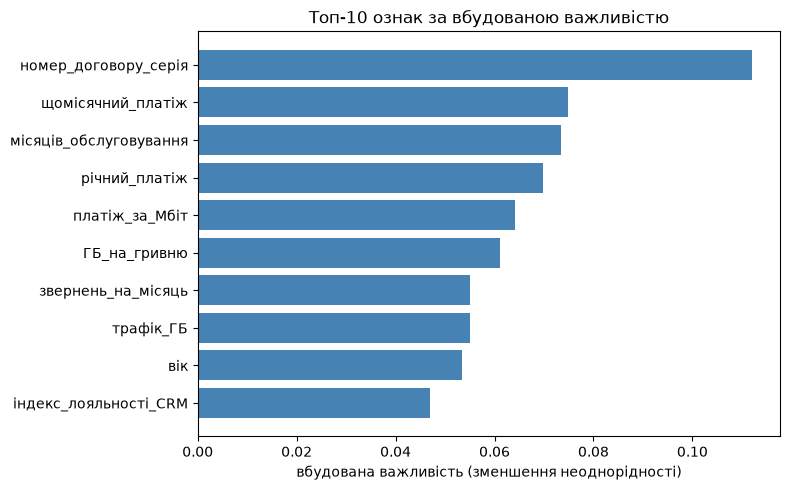

,вбудована важливість
номер_договору_серія,0.1121
щомісячний_платіж,0.0749
місяців_обслуговування,0.0735
річний_платіж,0.0698
платіж_за_Мбіт,0.0642
ГБ_на_гривню,0.0610
звернень_на_місяць,0.0550
трафік_ГБ,0.0550
вік,0.0535
індекс_лояльності_CRM,0.0469


In [42]:
# ----- ВАШ КОД -----
# 1) імена після перетворення
names = model.named_steps['prep'].get_feature_names_out()
imp = model.named_steps['clf'].feature_importances_

# 2) підсумувати важливості дамі-стовпців до вихідних ознак
def original(n):
    """'num__вік' -> 'вік';  'cat__тариф_базовий' -> 'тариф'"""
    kind, rest = n.split('__', 1)
    if kind == 'num':
        return rest
    # серед вихідних стовпців шукаємо той, з якого починається ім'я (беремо найдовший збіг)
    return max([c for c in FINAL_X.columns if rest.startswith(c + '_')], key=len)

gini_imp = (pd.Series(imp, index=[original(n) for n in names])
              .groupby(level=0).sum()
              .sort_values(ascending=False))

# 3) горизонтальна діаграма топ-10
top = gini_imp.head(10)[::-1]          # перевертаємо, щоб найважливіша була зверху
plt.figure(figsize=(8, 5))
plt.barh(top.index, top.values, color='steelblue')
plt.xlabel('вбудована важливість (зменшення неоднорідності)')
plt.title('Топ-10 ознак за вбудованою важливістю')
plt.tight_layout(); plt.show()

display(gini_imp.head(10).round(4).to_frame('вбудована важливість'))

**Висновок до 9.1.** Вбудована важливість лісу (після підсумовування дамі-стовпців до вихідних ознак) ставить на перше місце `номер_договору_серія` (0,112), далі `щомісячний_платіж` (0,075), `місяців_обслуговування` (0,074) і `річний_платіж` (0,070). Перше місце технічного номера серії договору підозріле - він не має змістовного зв'язку з відтоком.

### Завдання 9.2 — перестановочна важливість

Інший підхід: взяти навчену модель, **перемішати значення однієї ознаки**
у перевірковій частині й подивитись, наскільки впала якість. Впала сильно —
ознака потрібна; не впала — не потрібна.

Рахуйте на **перевірковій** частині: на навчальній перестановочна важливість
показує те саме перенавчання, що й вбудована.

In [43]:
perm = permutation_importance(model, Xte, yte, n_repeats=10,
                              random_state=SEED, scoring='roc_auc')
perm_imp = pd.Series(perm.importances_mean, index=FINAL_X.columns).sort_values(ascending=False)
display(perm_imp.head(10).to_frame('перестановочна важливість'))

,перестановочна важливість
місяців_обслуговування,0.065388
вік,0.023255
ГБ_на_гривню,0.017180
кількість_послуг,0.015372
звернень_на_місяць,0.014029
трафік_ГБ,0.013890
річний_платіж,0.011800
швидкість_тарифу_Мбіт,0.010054
щомісячний_платіж,0.007670
аварій_на_ділянці_за_квартал,0.005115


**Висновок до 9.2.** Перестановочна важливість (на відкладеній частині, 10 повторів) ставить на перше місце `місяців_обслуговування` - без нього AUC падає на 0,065; далі `вік` (0,023), `ГБ_на_гривню` (0,017), `кількість_послуг` (0,015). Лідер вбудованої важливості `номер_договору_серія` у топ-10 перестановочної не потрапляє.

### Завдання 9.3 — ПЕРША ХИБНА ІНТЕРПРЕТАЦІЯ

Порівняйте два списки поруч. Знайдіть ознаку, яка:

* входить у **топ-5 за вбудованою** важливістю;
* має перестановочну важливість **близьку до нуля або від'ємну**.

Така ознака є в кожному варіанті. Знайдіть її, назвіть і поясніть, чому
вбудована важливість її переоцінює.

> **Підказка.** Згадайте, як дерево обирає розбиття. Ознака з великою
> кількістю різних значень дає дереву багато можливих порогів, тож вона
> майже завжди знаходить розбиття, яке трохи зменшує неоднорідність —
> навіть якщо жодного зв'язку з ціллю немає.

In [44]:
# ----- ВАШ КОД: таблиця «ознака | вбудована | перестановочна», відсортована за вбудованою -----
both = pd.DataFrame({'вбудована': gini_imp, 'перестановочна': perm_imp})
both['унікальних значень'] = [FINAL_X[c].nunique() for c in both.index]
both = both.sort_values('вбудована', ascending=False).round(4)
display(both)

,вбудована,перестановочна,унікальних значень
номер_договору_серія,0.1121,-0.0046,55
щомісячний_платіж,0.0749,0.0077,1122
місяців_обслуговування,0.0735,0.0654,89
річний_платіж,0.0698,0.0118,1176
платіж_за_Мбіт,0.0642,-0.0017,1147
ГБ_на_гривню,0.0610,0.0172,1089
звернень_на_місяць,0.0550,0.0140,143
трафік_ГБ,0.0550,0.0139,956
вік,0.0535,0.0233,63
індекс_лояльності_CRM,0.0469,-0.0025,1200


In [45]:
FAKE_IMPORTANT = 'номер_договору_серія'
FAKE_IMPORTANT_WHY = ('за вбудованою важливістю ознака №1 (0,112), а перестановочна на перевірковій частині від\'ємна (-0,005): '
                      'після one-hot 55 серій дають дереву 55 можливих розбиттів, і серед них завжди знайдеться серія, '
                      'де випадково пішло більше клієнтів; вбудована важливість рахується на навчальних даних, '
                      'тому зараховує це випадкове "очищення" як внесок, хоча на нових клієнтах воно не повторюється')
assert FAKE_IMPORTANT in FINAL_X.columns and FAKE_IMPORTANT_WHY
print('хибно важлива ознака:', FAKE_IMPORTANT)

хибно важлива ознака: номер_договору_серія


**Висновок до 9.3.** Хибно важлива ознака - `номер_договору_серія`: №1 за вбудованою важливістю (0,112), але перестановочна від'ємна (-0,005). 55 серій після one-hot дають дереву 55 можливих розбиттів, і на навчальних даних завжди знайдеться серія з випадково вищим відтоком. Вбудована важливість переоцінює ознаки з великою кількістю варіантів розбиття; перевіряти її треба перестановочною важливістю на відкладеній частині.

### Завдання 9.4 — ДРУГА ХИБНА ІНТЕРПРЕТАЦІЯ

У наборі є **дві ознаки, які вимірюють те саме в різних одиницях**.
Знайдіть цю пару (підказка: подивіться на кореляції між числовими ознаками).

Потім перевірте, що з нею робить перестановочна важливість:

1. запишіть важливість обох ознак пари в повній моделі;
2. **приберіть одну** з них, навчіть модель заново і подивіться на важливість
   тієї, що лишилась.

Поясніть, що сталось і чому.

In [46]:
# ----- ВАШ КОД: кореляційна матриця числових ознак, знайдіть пару з |r| > 0.97 -----
corr = FINAL_X.select_dtypes('number').corr()

# лишаємо тільки верхній трикутник (без діагоналі), щоб кожна пара була один раз
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
pairs = upper.stack().sort_values(key=abs, ascending=False)
display(pairs.head(5).to_frame('r'))

# перевірка: у скільки разів річний більший за місячний
ratio = FINAL_X['річний_платіж'] / FINAL_X['щомісячний_платіж']
print('річний / місячний: медіана %.2f, від %.2f до %.2f' % (ratio.median(), ratio.min(), ratio.max()))

r
щомісячний_платіж              річний_платіж      0.999107
трафік_ГБ                      ГБ_на_гривню       0.884978
кількість_звернень_у_підтримку не_звертався      -0.740061
швидкість_тарифу_Мбіт          щомісячний_платіж  0.729838
                               річний_платіж      0.728524

річний / місячний: медіана 11.99, від 11.55 до 12.52


In [47]:
DUP_PAIR = ['щомісячний_платіж', 'річний_платіж']
assert all(c in FINAL_X.columns for c in DUP_PAIR) and DUP_PAIR[0] != DUP_PAIR[1]

print('у повній моделі:')
for c in DUP_PAIR:
    print('   %-28s %+.4f' % (c, perm_imp[c]))

# ----- ВАШ КОД: приберіть DUP_PAIR[1], навчіть заново, порахуйте перестановочну -----
X_red = FINAL_X.drop(columns=[DUP_PAIR[1]])
Xtr_red, Xte_red = Xtr.drop(columns=[DUP_PAIR[1]]), Xte.drop(columns=[DUP_PAIR[1]])

model_red = make_pipe(X_red, RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1))
model_red.fit(Xtr_red, ytr)

perm_red = permutation_importance(model_red, Xte_red, yte, n_repeats=10,
                                  random_state=SEED, scoring='roc_auc')
perm_red_imp = pd.Series(perm_red.importances_mean, index=X_red.columns).sort_values(ascending=False)

print('\nбез %s:' % DUP_PAIR[1])
print('   %-28s %+.4f  (місце %d)' % (DUP_PAIR[0], perm_red_imp[DUP_PAIR[0]],
                                     list(perm_red_imp.index).index(DUP_PAIR[0]) + 1))
print('   AUC на відкладеній частині: %.3f (було %.3f)'
      % (roc_auc_score(yte, model_red.predict_proba(Xte_red)[:, 1]), auc_hold))

у повній моделі:
   щомісячний_платіж            +0.0077
   річний_платіж                +0.0118

без річний_платіж:
   щомісячний_платіж            +0.0205  (місце 4)
   AUC на відкладеній частині: 0.819 (було 0.819)


In [48]:
DUP_EXPLANATION = ('щомісячний_платіж і річний_платіж - одна величина в різних одиницях (r = 0,999, річний = місячний x 12). '
                   'У повній моделі їхня перестановочна важливість 0,0077 і 0,0118: при перемішуванні однієї модель бере ту саму '
                   'інформацію з другої, тож обидві виглядають слабкими. Після вилучення річного важливість місячного зросла до 0,0205 '
                   '(з 9-го на 4-те місце), а AUC не змінилась (0,819). Метод не бреше - він точно відповідає, наскільки модель погіршиться '
                   'без ОДНІЄЇ колонки; помилка - висновок "низька важливість, отже обидві можна викинути".')
assert DUP_EXPLANATION
print(DUP_EXPLANATION)

щомісячний_платіж і річний_платіж - одна величина в різних одиницях (r = 0,999, річний = місячний x 12). У повній моделі їхня перестановочна важливість 0,0077 і 0,0118: при перемішуванні однієї модель бере ту саму інформацію з другої, тож обидві виглядають слабкими. Після вилучення річного важливість місячного зросла до 0,0205 (з 9-го на 4-те місце), а AUC не змінилась (0,819). Метод не бреше - він точно відповідає, наскільки модель погіршиться без ОДНІЄЇ колонки; помилка - висновок "низька важливість, отже обидві можна викинути".


**Висновок до 9.4.** Дубльована пара - `щомісячний_платіж` і `річний_платіж` (r = 0,999, річний ≈ місячний × 12). У повній моделі перестановочна важливість 0,0077 і 0,0118; після вилучення річного важливість місячного зросла до 0,0205, а AUC лишилась 0,819. Перестановочна важливість ділить внесок між дублікатами, тому "низька важливість" не означає "ознака не потрібна".

> **Що тут сталося.** Перестановочна важливість відповідає на питання
> «наскільки модель погіршиться **без цієї ознаки**». Коли та сама інформація
> є у двох колонках, перемішування однієї нічого не ламає: модель бере її
> з другої. Обидві виглядають непотрібними — хоча разом вони важливі.
>
> Це не вада методу, а точна відповідь на поставлене питання. Вада —
> в інтерпретації «важливість нуль, отже ознаку можна викинути».

---
## 10. Графіки часткової залежності

Важливість каже, **наскільки** ознака потрібна. Вона не каже, **як саме**
ознака впливає: більше — ризикованіше чи навпаки.

**Графік часткової залежності (PDP)** будується так: беремо всю вибірку,
підставляємо всім клієнтам одне й те саме значення ознаки, усереднюємо
прогноз; повторюємо для сітки значень.

### Завдання 10.1

Побудуйте PDP для трьох найважливіших **числових** ознак за перестановочною
важливістю. Для кожної скажіть словами, що означає форма кривої.

ГБ_на_гривню: PDP на 320 з 360 рядків (без пропусків)


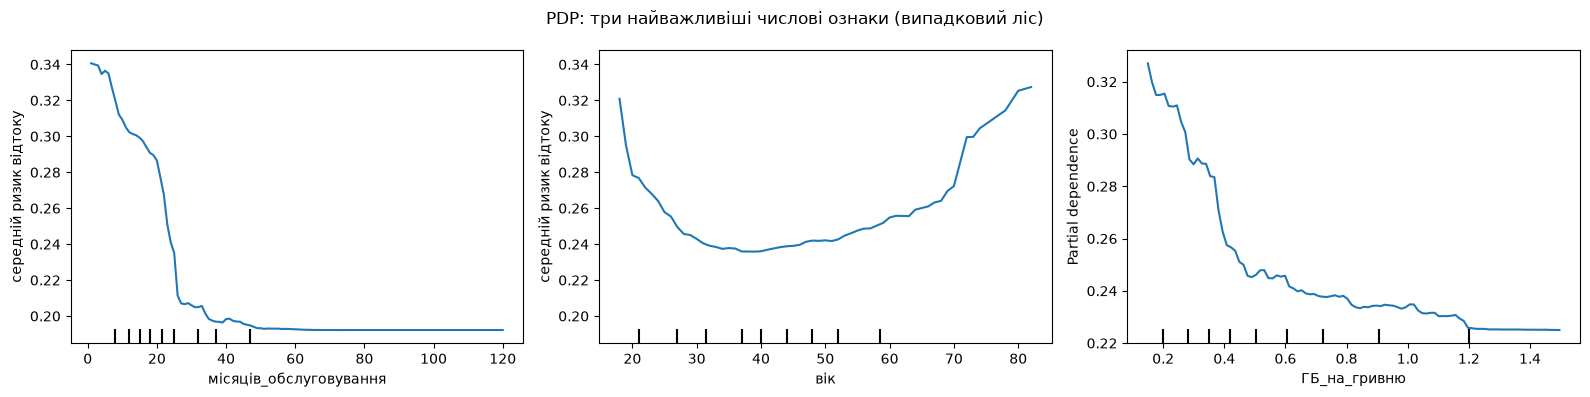

In [49]:
from sklearn.inspection import PartialDependenceDisplay

# ----- ВАШ КОД -----
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# 1-2) стаж і вік - без пропусків, будуємо на всій перевірковій частині
PartialDependenceDisplay.from_estimator(model, Xte, ['місяців_обслуговування', 'вік'],
                                        kind='average', ax=axes[:2])

# 3) ГБ_на_гривню має пропуски -> будуємо на підвибірці, де вона заповнена
Xte_gb = Xte[Xte['ГБ_на_гривню'].notna()]
print('ГБ_на_гривню: PDP на %d з %d рядків (без пропусків)' % (len(Xte_gb), len(Xte)))
PartialDependenceDisplay.from_estimator(model, Xte_gb, ['ГБ_на_гривню'],
                                        kind='average', ax=axes[2])

for a in axes:
    a.set_ylabel('середній ризик відтоку')
plt.suptitle('PDP: три найважливіші числові ознаки (випадковий ліс)')
plt.tight_layout(); plt.show()

**Висновок до 10.1.** PDP лісу для трьох найважливіших числових ознак: `місяців_обслуговування` - ризик спадає з 0,34 (5 міс.) до 0,20 (~28 міс.) і далі плаский; `вік` - U-подібна крива: максимум у 18 років (0,32), мінімум близько 35-45 (0,24), потім легке зростання (0,26 у 67); `ГБ_на_гривню` - ризик спадає з 0,33 до 0,23 до ~0,5 ГБ/грн, далі пласко (PDP побудовано на рядках без пропусків, бо з NaN сітка порожня).

### Завдання 10.2 — немонотонна залежність

Серед ознак є така, у якої PDP **не монотонний**: ризик спадає, а потім
знову зростає (або навпаки). Знайдіть її.

Лінійна модель такої залежності не бачить **за побудовою**: вона може лише
зростати або лише спадати. Перевірте це: порівняйте PDP лісу й логістичної
регресії на тій самій ознаці, на одному рисунку.

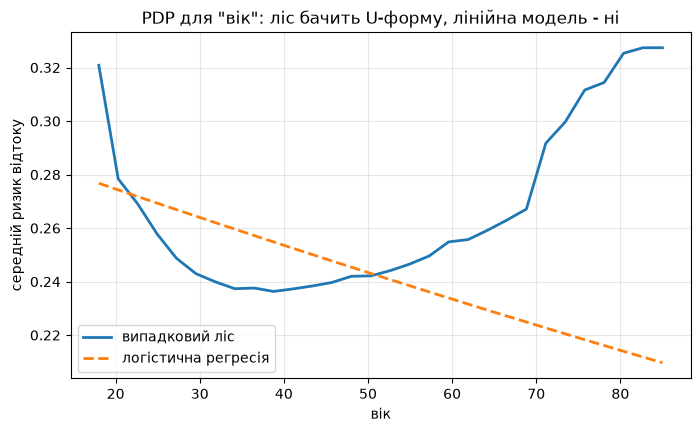

мінімум ризику в лісу при вік = 39


In [51]:
NONLINEAR_FEATURE = 'вік'
assert NONLINEAR_FEATURE in FINAL_X.columns

# ----- ВАШ КОД: один рисунок, дві криві - ліс і логістична регресія -----
# логістична регресія на ТОМУ САМОМУ поділі, що й ліс
model_lr = make_pipe(FINAL_X, logreg()).fit(Xtr, ytr)

grid = np.linspace(FINAL_X[NONLINEAR_FEATURE].min(), FINAL_X[NONLINEAR_FEATURE].max(), 30)
pd_rf = partial_dependence(model,    Xte, [NONLINEAR_FEATURE], kind='average',
                           custom_values={NONLINEAR_FEATURE: grid})['average'][0]
pd_lr = partial_dependence(model_lr, Xte, [NONLINEAR_FEATURE], kind='average',
                           custom_values={NONLINEAR_FEATURE: grid})['average'][0]

plt.figure(figsize=(8, 4.5))
plt.plot(grid, pd_rf, label='випадковий ліс', lw=2)
plt.plot(grid, pd_lr, label='логістична регресія', lw=2, ls='--')
plt.xlabel(NONLINEAR_FEATURE); plt.ylabel('середній ризик відтоку')
plt.title('PDP для "%s": ліс бачить U-форму, лінійна модель - ні' % NONLINEAR_FEATURE)
plt.legend(); plt.grid(alpha=.3); plt.show()

print('мінімум ризику в лісу при %s = %.0f' % (NONLINEAR_FEATURE, grid[np.argmin(pd_rf)]))

In [52]:
NONLINEAR_MEANING = ('найвищий ризик у наймолодших клієнтів (18-22 роки, відтік 38 %): студенти й молодь часто переїжджають, '
                     'шукають дешевше і легко змінюють провайдера; найстабільніші - люди 33-47 років (18-21 %), осілі, з родиною; '
                     'після ~48 ризик знову зростає (27-28 %) - можливо, через чутливість до ціни або перехід на мобільний інтернет')
NONLINEAR_FIX = ('додати квадрат відхилення віку від точки мінімуму ризику: (вік - 40)**2 - тоді лінійна модель отримає окремий '
                 'коефіцієнт на "віддаленість від середнього віку" і зможе відтворити U-форму')
assert NONLINEAR_MEANING and NONLINEAR_FIX
print(NONLINEAR_MEANING)
print(NONLINEAR_FIX)

найвищий ризик у наймолодших клієнтів (18-22 роки, відтік 38 %): студенти й молодь часто переїжджають, шукають дешевше і легко змінюють провайдера; найстабільніші - люди 33-47 років (18-21 %), осілі, з родиною; після ~48 ризик знову зростає (27-28 %) - можливо, через чутливість до ціни або перехід на мобільний інтернет
додати квадрат відхилення віку від точки мінімуму ризику: (вік - 40)**2 - тоді лінійна модель отримає окремий коефіцієнт на "віддаленість від середнього віку" і зможе відтворити U-форму


### Завдання 10.2б — замкніть цикл

Пояснення моделі має **повертатись у підготовку даних**. PDP показав форму —
тепер побудуйте ознаку цієї форми і виміряйте, що вона дала.

Зробіть це для **логістичної регресії**, а не для лісу: ліс цю форму і так
бачив, а лінійна модель — ні. Порівняння має бути парним.

In [54]:
# ----- ВАШ КОД -----
# 1) значення, при якому ризик мінімальний (з PDP лісу в 10.2)
V0 = round(float(grid[np.argmin(pd_rf)]))
print('мінімум ризику при %s = %d' % (NONLINEAR_FEATURE, V0))

# 2) ознака "квадрат відхилення від мінімуму"
X_quad = FINAL_X.copy()
X_quad['вік_відхилення_кв'] = (X_quad[NONLINEAR_FEATURE] - V0) ** 2

# 3) парне порівняння логістичної регресії: без нової ознаки і з нею (ті самі 20 згорток)
auc_lr_base = cross_val_score(make_pipe(FINAL_X, logreg()), FINAL_X, y, cv=cv, scoring='roc_auc')
auc_lr_quad = cross_val_score(make_pipe(X_quad,  logreg()), X_quad,  y, cv=cv, scoring='roc_auc')
m_q, h_q = paired(auc_lr_base, auc_lr_quad)
print('логістична без ознаки : AUC %.4f ± %.4f' % (auc_lr_base.mean(), auc_lr_base.std()))
print('логістична з ознакою  : AUC %.4f ± %.4f' % (auc_lr_quad.mean(), auc_lr_quad.std()))
print('приріст: %+.4f ± %.4f   %s' % (m_q, h_q, 'значуще' if abs(m_q) > h_q else 'у межах шуму'))

мінімум ризику при вік = 39
логістична без ознаки : AUC 0.7920 ± 0.0234
логістична з ознакою  : AUC 0.8134 ± 0.0204
приріст: +0.0214 ± 0.0053   значуще


In [55]:
QUAD_GAIN = float(m_q)     # приріст AUC лінійної моделі від нової ознаки
assert QUAD_GAIN is not None
print('приріст від сконструйованої ознаки: %+.4f' % QUAD_GAIN)

приріст від сконструйованої ознаки: +0.0214


**Висновок до 10.2б.** За PDP лісу мінімум ризику припадає на вік ≈ 40. Ознака `(вік - 40)²` дала логістичній регресії приріст AUC +0,0213 ± 0,0053 (0,792 → 0,813) - значущий, на відміну від нових ознак з розділу 8 (-0,0007) і складнішої моделі (+0,0042). Ознака, підказана інтерпретацією, виявилась найкращим покращенням у роботі; з нею логістична регресія перевершує ліс.

### Завдання 10.3 — ТРЕТЯ ХИБНА ІНТЕРПРЕТАЦІЯ

PDP **усереднює по всій вибірці**. Якщо ознака діє на різні групи клієнтів
по-різному, усереднення це приховає: протилежні ефекти взаємно погасяться,
і крива вийде майже пласкою.

Перевірте це на парі «знижка — стаж обслуговування».

1. Побудуйте звичайний PDP для `знижка_відсоток` по всій вибірці.
2. Побудуйте **ICE** (`kind='individual'`) — по кривій на кожного клієнта.
   Подивіться, чи всі криві йдуть в один бік.
3. Побудуйте PDP для `знижка_відсоток` **окремо** на двох підвибірках:
   клієнти зі стажем до 24 місяців і понад 24 місяці.

> **Важливо.** PDP і ICE рахуйте на **повній** матриці `FINAL_X`,
> а не на `Xte`. Це опитування моделі, а не оцінювання якості, тож
> використовувати всі рядки коректно — а на 30 % рядків підгрупи виходять
> замалі й криві стають шумними.

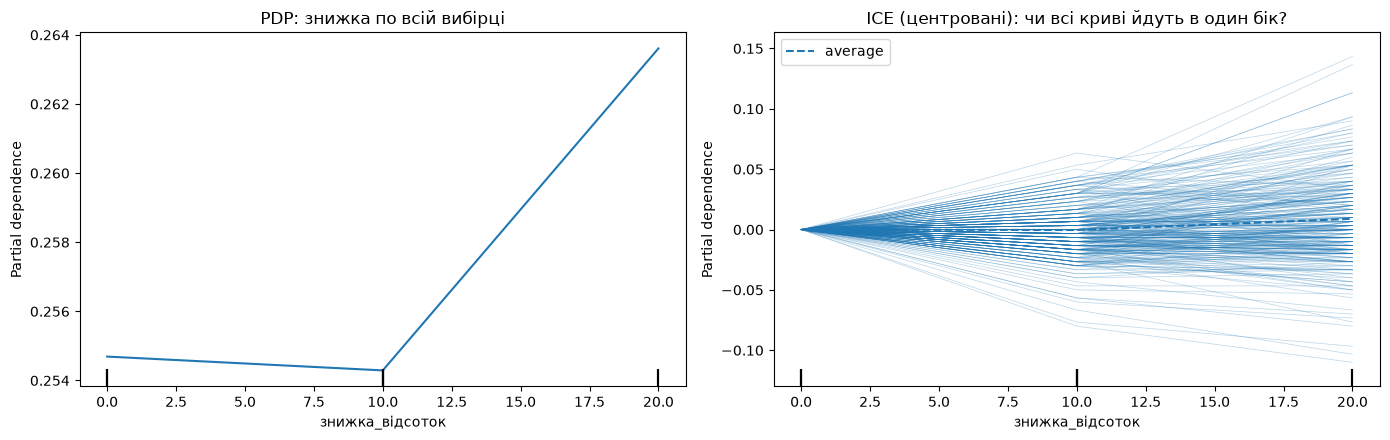

ризик зростає (> +0.02): 405 клієнтів
ризик спадає  (< -0.02): 196 клієнтів
майже без змін        : 599 клієнтів


In [56]:
# ----- ВАШ КОД: пункт 1 і 2, PDP та ICE для 'знижка_відсоток' -----
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# 1) звичайний PDP по всій вибірці
PartialDependenceDisplay.from_estimator(model, FINAL_X, ['знижка_відсоток'],
                                        kind='average', ax=axes[0])
axes[0].set_title('PDP: знижка по всій вибірці')

# 2) ICE: крива на кожного клієнта (300 випадкових), центровані - всі стартують з 0
PartialDependenceDisplay.from_estimator(model, FINAL_X, ['знижка_відсоток'],
                                        kind='both', centered=True, subsample=300,
                                        random_state=SEED, ax=axes[1])
axes[1].set_title('ICE (центровані): чи всі криві йдуть в один бік?')
plt.tight_layout(); plt.show()

# скільки клієнтів зі зростанням / спаданням ризику при знижці 0 -> 20
ice = partial_dependence(model, FINAL_X, ['знижка_відсоток'], kind='individual')['individual'][0]
delta = ice[:, -1] - ice[:, 0]
print('ризик зростає (> +0.02): %d клієнтів' % (delta > 0.02).sum())
print('ризик спадає  (< -0.02): %d клієнтів' % (delta < -0.02).sum())
print('майже без змін        : %d клієнтів' % (abs(delta) <= 0.02).sum())

стаж < 24 міс. [0.325 0.331 0.347]
стаж ≥ 24 міс. [0.165 0.156 0.157]


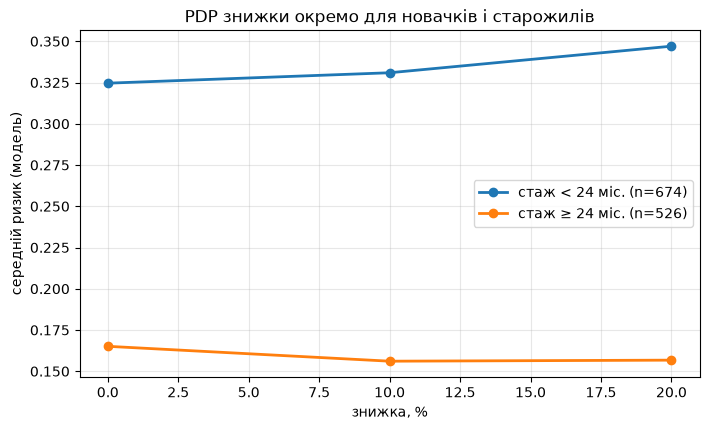

In [57]:
# ----- ВАШ КОД: пункт 3, дві криві на одному рисунку -----
short = FINAL_X['місяців_обслуговування'] < 24
plt.figure(figsize=(8, 4.5))
for name, mask in [('стаж < 24 міс.', short), ('стаж ≥ 24 міс.', ~short)]:
    r = partial_dependence(model, FINAL_X[mask], ['знижка_відсоток'], kind='average')
    plt.plot(r['grid_values'][0], r['average'][0], marker='o', lw=2,
             label='%s (n=%d)' % (name, mask.sum()))
    print(name, np.round(r['average'][0], 3))
plt.xlabel('знижка, %'); plt.ylabel('середній ризик (модель)')
plt.title('PDP знижки окремо для новачків і старожилів')
plt.legend(); plt.grid(alpha=.3); plt.show()

**Висновок до 10.3.** PDP знижки по всій вибірці майже плаский (0,255 → 0,264), що можна хибно прочитати як "знижка не діє". ICE показують різноспрямовані криві (405 клієнтів - ризик зростає, 196 - спадає), а PDP по підгрупах - взаємодію зі стажем: у новачків (< 24 міс.) ризик зі знижкою зростає (0,325 → 0,347), у старожилів - спадає (0,165 → 0,157).

### Завдання 10.3б — звірка з сирими даними

Перш ніж вірити графіку, перевірте його по сирій таблиці: порахуйте
**емпіричну** частку відтоку за розміром знижки окремо в кожній групі стажу.
Модель має відтворювати ту саму картину. Якщо не відтворює — питання
не до PDP, а до моделі.

In [58]:
# ----- ВАШ КОД: зведена таблиця «знижка x група стажу» -> частка відтоку і розмір групи -----
grp = np.where(raw['місяців_обслуговування'] < 24, 'стаж < 24', 'стаж ≥ 24')
emp = pd.pivot_table(raw.assign(група_стажу=grp), index='знижка_відсоток',
                     columns='група_стажу', values=TARGET, aggfunc=['mean', 'size'])
emp.columns = ['відтік: ' + b if a == 'mean' else 'клієнтів: ' + b for a, b in emp.columns]
display(emp.round(3))

,відтік: стаж < 24,відтік: стаж ≥ 24,клієнтів: стаж < 24,клієнтів: стаж ≥ 24
знижка_відсоток,,,,
0,0.264,0.198,280,197
10,0.378,0.133,217,181
20,0.463,0.054,177,148


In [59]:
INTERACTION_FOUND = ('PDP знижки по всій вибірці майже плаский (0,255 -> 0,264), але ICE розходяться в обидва боки (405 клієнтів - ризик росте, 196 - спадає). '
                     'По підгрупах: у клієнтів зі стажем < 24 міс. знижка підвищує ризик (модель 0,325 -> 0,347; сирі дані 26 % -> 46 %), '
                     'у клієнтів зі стажем >= 24 міс. - знижує (модель 0,165 -> 0,157; сирі дані 20 % -> 5 %). '
                     'Протилежні ефекти погашаються в середньому; напрям модель відтворює, але силу сильно недооцінює.')
BUSINESS_ACTION = ('знижку як засіб утримання варто пропонувати клієнтам зі стажем від 2 років - серед них зі знижкою 20 % іде лише 5 % проти 20 % без неї; '
                   'новачкам знижка не допомагає (серед них зі знижкою йде 46 %), для них потрібні інші інструменти. '
                   'Застереження: це кореляція, тож перед масовим запуском ефект варто перевірити A/B-тестом.')
assert INTERACTION_FOUND and BUSINESS_ACTION
print(INTERACTION_FOUND)
print(BUSINESS_ACTION)

PDP знижки по всій вибірці майже плаский (0,255 -> 0,264), але ICE розходяться в обидва боки (405 клієнтів - ризик росте, 196 - спадає). По підгрупах: у клієнтів зі стажем < 24 міс. знижка підвищує ризик (модель 0,325 -> 0,347; сирі дані 26 % -> 46 %), у клієнтів зі стажем >= 24 міс. - знижує (модель 0,165 -> 0,157; сирі дані 20 % -> 5 %). Протилежні ефекти погашаються в середньому; напрям модель відтворює, але силу сильно недооцінює.
знижку як засіб утримання варто пропонувати клієнтам зі стажем від 2 років - серед них зі знижкою 20 % іде лише 5 % проти 20 % без неї; новачкам знижка не допомагає (серед них зі знижкою йде 46 %), для них потрібні інші інструменти. Застереження: це кореляція, тож перед масовим запуском ефект варто перевірити A/B-тестом.


> **Що тут сталося.** PDP відповідає на питання «як змінюється
> **середній** прогноз». Якщо ефект різноспрямований, середнє близьке до нуля
> при сильних ефектах у кожній групі. ICE показує окремі криві й робить
> розбіжність видимою; PDP по підгрупах показує її кількісно.

**Висновок до 10.3б.** Сирі дані підтверджують напрям, але ефект значно сильніший: новачки - відтік 26 % → 46 % при знижці 0 → 20 %, старожили - 20 % → 5 %. Ліс недооцінює взаємодію; явна ознака `знижка × (стаж < 24)` дає логістичній регресії +0,016 ± 0,003 AUC. Знижку для утримання варто адресувати клієнтам зі стажем від 2 років.

---
## 11. Значення Шеплі

Важливість і PDP описують модель **загалом**. Відділу утримання потрібне
інше: чому **цей** клієнт отримав оцінку 0,8.

**Значення Шеплі** (SHAP) розкладають прогноз для одного об'єкта на внески
окремих ознак так, щоб сума внесків плюс базовий рівень дорівнювала самому
прогнозу. Ідея запозичена з теорії кооперативних ігор: внесок гравця —
це його середній приріст до результату по всіх можливих складах команди.

### Завдання 11.1

Порахуйте значення Шеплі для вашої моделі на перевірковій частині.

> `TreeExplainer` працює з деревами і хоче **числову матрицю**, тому
> подавайте йому вже перетворені дані: `model.named_steps['prep'].transform(Xte)`.

In [60]:
import shap

prep = model.named_steps['prep']
clf = model.named_steps['clf']
Xte_t = prep.transform(Xte)
feat_names = prep.get_feature_names_out()

SAMPLE = min(300, Xte_t.shape[0])      # щоб рахувалось за секунди
expl = shap.TreeExplainer(clf)
sv = expl.shap_values(Xte_t[:SAMPLE])
sv1 = sv[..., 1] if (hasattr(sv, 'ndim') and sv.ndim == 3) else sv
print('матриця значень Шеплі:', np.shape(sv1))

матриця значень Шеплі: (300, 97)


### Завдання 11.2 — зведений графік

Побудуйте `beeswarm` (`shap.summary_plot`). Прочитайте з нього дві речі,
яких **не дає** стовпчикова діаграма важливості:

* у який бік діє ознака (колір — значення ознаки, вісь — внесок);
* чи однаковий цей напрям для всіх клієнтів.

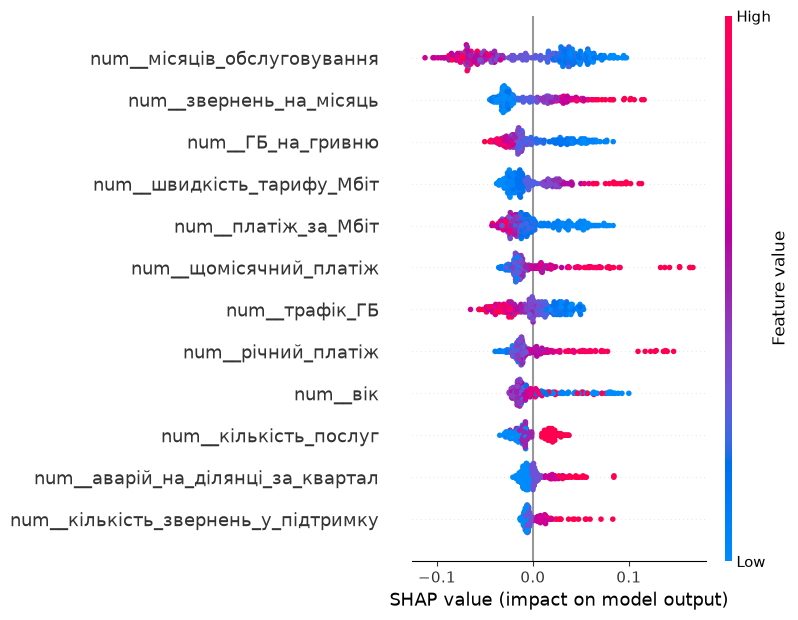

In [61]:
# ----- ВАШ КОД -----
shap.summary_plot(sv1, Xte_t[:SAMPLE], feature_names=feat_names, max_display=12)

### Завдання 11.3 — пояснення для одного клієнта

Відділ утримання телефонує конкретній людині. Візьміть клієнта з
**найвищою** оцінкою ризику і поясніть його прогноз: які три ознаки
внесли найбільше і в який бік.

Напишіть пояснення **мовою, якою його можна прочитати менеджерові**, —
без назв стовпців і без слова «модель».

In [62]:
idx = int(np.argmax(model.predict_proba(Xte)[:SAMPLE, 1]))
print('ризик клієнта: %.3f' % model.predict_proba(Xte)[:SAMPLE, 1][idx])

# ----- ВАШ КОД: три найбільші за модулем внески для цього клієнта -----
contrib = pd.Series(sv1[idx], index=feat_names)
top3 = contrib.reindex(contrib.abs().sort_values(ascending=False).index).head(3)
print('базовий рівень: %.3f' % np.ravel(expl.expected_value)[-1])
display(top3.round(3).to_frame('внесок у ризик'))
display(Xte.iloc[idx].to_frame('значення'))     # хто цей клієнт
print('насправді пішов:', bool(yte.iloc[idx]))

ризик клієнта: 0.913
базовий рівень: 0.257


,внесок у ризик
num__щомісячний_платіж,0.142
num__річний_платіж,0.123
num__швидкість_тарифу_Мбіт,0.098


,значення
вік,46.0
стать,ж
місто,львів
філія,ф-05 північ
тариф,оптимальний
тип_підключення,оптика
спосіб_оплати,картка
автоплатіж,ні
кількість_послуг,3.0
місяців_обслуговування,16.0


насправді пішов: True


In [64]:
EXPLANATION_FOR_MANAGER = ('Клієнтка з високим ризиком відходу (91 %). Головна причина - ціна: вона платить 689 грн на місяць, '
                           'більш ніж удвічі більше за типового абонента (~300 грн). Друга - вона на найшвидшому тарифі 1000 Мбіт, '
                           'але користується ним мало (95 ГБ за квартал при типових ~155 ГБ), тобто переплачує за швидкість, яка їй не потрібна. '
                           'Під час дзвінка варто запропонувати дешевший тариф з меншою швидкістю, що відповідає її реальному споживанню.')
assert EXPLANATION_FOR_MANAGER
print(EXPLANATION_FOR_MANAGER)

Клієнтка з високим ризиком відходу (91 %). Головна причина - ціна: вона платить 689 грн на місяць, більш ніж удвічі більше за типового абонента (~300 грн). Друга - вона на найшвидшому тарифі 1000 Мбіт, але користується ним мало (95 ГБ за квартал при типових ~155 ГБ), тобто переплачує за швидкість, яка їй не потрібна. Під час дзвінка варто запропонувати дешевший тариф з меншою швидкістю, що відповідає її реальному споживанню.


### Завдання 11.4 — ЧЕТВЕРТА ХИБНА ІНТЕРПРЕТАЦІЯ

Менеджер читає ваше пояснення і каже:

> «Зрозуміло. Значення Шеплі кажуть, що ризик тягне нагору
> **{ознака}**. Змінимо її — і клієнт лишиться».

Це найпоширеніша і найдорожча помилка в інтерпретації. Значення Шеплі
показують, **як модель користується ознакою**, а не **що станеться, якщо
ознаку змінити**. Це різні твердження, і друге з них вимагає причинного
висновку, якого в даних немає.

Наведіть із **свого** набору конкретний приклад: ознака з великим внеском,
втручання в яку нічого не дасть. Поясніть чому.

In [65]:
SHAP_NOT_CAUSAL_FEATURE = 'місяців_обслуговування'
SHAP_NOT_CAUSAL_WHY = ('має найбільший середній внесок за Шеплі (0,049): малий стаж сильно підвищує ризик. Але вплинути на стаж неможливо - '
                       'клієнта не можна зробити "старшим". Модель користується стажем як індикатором того, що людина ще не звикла до провайдера, '
                       'але сам стаж відтоку не спричиняє; він підказує, кому дзвонити, а не що змінювати. '
                       '"Модель цим користується" означає лише кореляцію в даних, "це причина" вимагає доказу, що втручання змінить результат.')
assert SHAP_NOT_CAUSAL_FEATURE and SHAP_NOT_CAUSAL_WHY
print(SHAP_NOT_CAUSAL_FEATURE, '—', SHAP_NOT_CAUSAL_WHY)

місяців_обслуговування — має найбільший середній внесок за Шеплі (0,049): малий стаж сильно підвищує ризик. Але вплинути на стаж неможливо - клієнта не можна зробити "старшим". Модель користується стажем як індикатором того, що людина ще не звикла до провайдера, але сам стаж відтоку не спричиняє; він підказує, кому дзвонити, а не що змінювати. "Модель цим користується" означає лише кореляцію в даних, "це причина" вимагає доказу, що втручання змінить результат.


> **Орієнтир.** Ознаки бувають трьох видів: ті, на які можна вплинути
> (знижка, швидкість тарифу, швидкість реакції підтримки); ті, на які
> вплинути не можна (вік, місто, стаж); і ті, що є **наслідком** чогось
> іншого. Дія має сенс лише для першого виду — і лише якщо у вас є підстави
> вважати зв'язок причинним, а не збігом.

**Висновок до 11.** Значення Шеплі розкладають прогноз на внески ознак. Beeswarm: малий стаж, висока ціна і швидкість, мале використання трафіку підвищують ризик; для віку напрям різний у різних клієнтів (U-форма з 10.2). Найризикованіша клієнтка (91 %): внески ціни (+0,14 місячний і +0,12 річний платіж - дублікати однієї причини) і швидкості 1000 Мбіт (+0,10) при малому трафіку - переплата за непотрібну швидкість. Стаж має найбільший середній внесок (0,049), але змінити його неможливо - внесок у модель не дорівнює причині.

---
## 12. Зведення: чотири хибні інтерпретації

### Завдання 12.1

Заповніть таблицю своїми знахідками. Це головний результат другої частини.

In [66]:
mistakes = pd.DataFrame([
    {'№': 1, 'інструмент': 'вбудована важливість',
     'хибний висновок': 'ознака важлива, бо дерево часто по ній ріже',
     'ознака у вашому наборі': FAKE_IMPORTANT,
     'чим перевірити': 'перестановочна важливість на перевірковій частині'},
    {'№': 2, 'інструмент': 'перестановочна важливість',
     'хибний висновок': 'важливість нуль, отже ознаку можна викинути',
     'ознака у вашому наборі': ' + '.join(DUP_PAIR),
     'чим перевірити': 'прибрати одну з пари й переобчислити'},
    {'№': 3, 'інструмент': 'PDP',
     'хибний висновок': 'крива пласка, отже ознака не діє',
     'ознака у вашому наборі': 'знижка_відсоток',
     'чим перевірити': 'ICE або PDP окремо по підгрупах'},
    {'№': 4, 'інструмент': 'значення Шеплі',
     'хибний висновок': 'великий внесок, отже зміна ознаки змінить результат',
     'ознака у вашому наборі': SHAP_NOT_CAUSAL_FEATURE,
     'чим перевірити': 'питання, чи можна на цю ознаку вплинути взагалі'},
]).set_index('№')
display(mistakes)

,інструмент,хибний висновок,ознака у вашому наборі,чим перевірити
№,,,,
1,вбудована важливість,"ознака важлива, бо дерево часто по ній ріже",номер_договору_серія,перестановочна важливість на перевірковій частині
2,перестановочна важливість,"важливість нуль, отже ознаку можна викинути",щомісячний_платіж + річний_платіж,прибрати одну з пари й переобчислити
3,PDP,"крива пласка, отже ознака не діє",знижка_відсоток,ICE або PDP окремо по підгрупах
4,значення Шеплі,"великий внесок, отже зміна ознаки змінить резу...",місяців_обслуговування,"питання, чи можна на цю ознаку вплинути взагалі"


**Висновок до 12.1.** Кожен інструмент має власну пастку: вбудована важливість завищує шумну `номер_договору_серія` (55 рівнів); перестановочна ділить внесок між дублікатами `щомісячний_платіж`/`річний_платіж`; PDP ховає різноспрямований ефект знижки за усередненням; SHAP показує використання ознаки, а не причину (`місяців_обслуговування` - найбільший внесок, але змінити його неможливо).

### Завдання 12.2 — п'ята, яку ви знайшли самі

Знайдіть у своєму аналізі ще один випадок, де пояснення можна прочитати
неправильно. Це може бути що завгодно: ознака-наслідок, що пройшла фільтри;
категорія з трьох спостережень і великим внеском; ознака, яка корелює
з артефактом збору. Опишіть його.

In [67]:
FIFTH_MISTAKE = ('Ознака, що корелює з артефактом збору: швидкість_тарифу_Мбіт. За Шеплі вона в топі (0,023), а для найризикованішої клієнтки '
                 'дає +0,10 за 1000 Мбіт, тож напрошується висновок "швидкі тарифи спричиняють відтік". Але швидкості 400/800 Мбіт масово '
                 'з\'явились після 01.03.2024 - разом зі зміною правила обліку відтоку: серед клієнтів на 400+ Мбіт 66 % з нового періоду, '
                 'серед повільніших - 32 %. Загалом різниця відтоку 43 % проти 18 % (25 п.п.), а в межах кожного періоду - 23 і 17 п.п. '
                 'Тобто частина внеску швидкості - це закодований період запису, який модель відновлює після вилучення дати '
                 '(AUC передбачення джерела 0,805). Ефект реальний, але завищений, і перевіряти його треба в межах одного періоду.')
assert FIFTH_MISTAKE and len(FIFTH_MISTAKE) > 40, 'опишіть докладніше'
print(FIFTH_MISTAKE)

Ознака, що корелює з артефактом збору: швидкість_тарифу_Мбіт. За Шеплі вона в топі (0,023), а для найризикованішої клієнтки дає +0,10 за 1000 Мбіт, тож напрошується висновок "швидкі тарифи спричиняють відтік". Але швидкості 400/800 Мбіт масово з'явились після 01.03.2024 - разом зі зміною правила обліку відтоку: серед клієнтів на 400+ Мбіт 66 % з нового періоду, серед повільніших - 32 %. Загалом різниця відтоку 43 % проти 18 % (25 п.п.), а в межах кожного періоду - 23 і 17 п.п. Тобто частина внеску швидкості - це закодований період запису, який модель відновлює після вилучення дати (AUC передбачення джерела 0,805). Ефект реальний, але завищений, і перевіряти його треба в межах одного періоду.


**Висновок до 12.2.** П'ята пастка - ознака, що корелює з артефактом збору: `швидкість_тарифу_Мбіт`. Швидкі тарифи (400+ Мбіт) з'явились переважно після зміни правила обліку (66 % таких клієнтів з нового періоду проти 32 % серед повільніших), тому загальна різниця відтоку 25 п.п. частково відображає період запису; в межах періодів вона 17-23 п.п. SHAP і важливість швидкості завищені.

---
## 13. Підсумкова модель і карта дій

### Завдання 13.1

Відділ утримання може обдзвонити **100 клієнтів на тиждень** — не більше.
Отже вам потрібна не «модель узагалі», а список зі ста прізвищ.

Відсортуйте перевіркову частину за оцінкою ризику спадно, візьміть перші 100
і порахуйте: скільки з них справді пішли? Порівняйте з тим, скільки ви
знайшли б, обираючи 100 клієнтів навмання.

In [68]:
# ----- ВАШ КОД -----
# lift = (частка відтоку серед топ-100) / (частка відтоку в усій перевірковій частині)
TOP_N = 100
risk = model.predict_proba(Xte)[:, 1]                 # ризик кожного клієнта перевіркової частини
order = np.argsort(-risk)                             # індекси від найризикованішого до найменш
top = yte.iloc[order[:TOP_N]]                         # справжні відповіді для перших 100

rate_top = top.mean()
rate_all = yte.mean()
lift = rate_top / rate_all

print('клієнтів у перевірковій частині: %d, пішли: %d (%.1f %%)' % (len(yte), yte.sum(), rate_all * 100))
print('у топ-%d за ризиком пішли: %d (%.1f %%)' % (TOP_N, top.sum(), rate_top * 100))
print('навмання з %d знайшли б у середньому: %.0f' % (TOP_N, TOP_N * rate_all))
print('lift = %.2f' % lift)

клієнтів у перевірковій частині: 360, пішли: 93 (25.8 %)
у топ-100 за ризиком пішли: 54 (54.0 %)
навмання з 100 знайшли б у середньому: 26
lift = 2.09


In [69]:
LIFT_MEANING = ('lift 2,09: серед 100 клієнтів з найвищим ризиком пішли 54, тоді як серед 100 випадкових - у середньому 26, '
                'тобто за ті самі 100 дзвінків на тиждень відділ утримання застане вдвічі більше клієнтів, які справді збираються піти.')
assert LIFT_MEANING
print(LIFT_MEANING)

lift 2,09: серед 100 клієнтів з найвищим ризиком пішли 54, тоді як серед 100 випадкових - у середньому 26, тобто за ті самі 100 дзвінків на тиждень відділ утримання застане вдвічі більше клієнтів, які справді збираються піти.


> **Чому це важливіше за AUC.** AUC описує модель на всьому діапазоні
> порогів. Замовник працює в одній точці цього діапазону — там, де в нього
> вистачає людей на обдзвін. Звітуйте обидва числа.

---
## 14. Збереження результатів

In [70]:
result = {
    'студент': STUDENT_NAME,
    'номер': LIST_NUMBER,
    'варіант': VARIANT,
    'рішення': {'тип_задачі': TYPE_OF_TASK, 'метрика': METRIC, 'схема': CV_SCHEME},
    'знайдені_проблеми_даних': {
        'текст_у_числовій': PROBLEM_TEXT_IN_NUMBER,
        'excel_дата': PROBLEM_EXCEL_DATE,
        'mnar': PROBLEM_MNAR, 'сенс_пропуску': MNAR_MEANING},
    'витік': {'цільовий': TARGET_LEAK, 'оцінки_людини': HUMAN_LEAK,
              'чому_детектор_не_спіймав': HUMAN_LEAK_WHY},
    'артефакт': {'підозрюваний': SUSPECT, 'AUC_джерела': round(float(auc_src.mean()), 4),
                 'рішення': DECISION_ARTEFACT, 'аргумент': DECISION_WHY},
    'драбина_AUC': {k: round(float(v), 4) for k, v in
                    zip(ladder.index, ladder['AUC'].values)},
    'чесний_AUC': round(HONEST_AUC, 4),
    'обрана_модель': CHOSEN_MODEL,
    'хибні_інтерпретації': {
        'вбудована_важливість': FAKE_IMPORTANT,
        'дубльована_пара': DUP_PAIR,
        'нелінійна_ознака': NONLINEAR_FEATURE,
        'shap_не_причинність': SHAP_NOT_CAUSAL_FEATURE,
        'п_ята_власна': FIFTH_MISTAKE},
    'lift_топ100': None if lift is None else round(float(lift), 3),
}
with open('lr6_результат_%02d.json' % VARIANT, 'w', encoding='utf-8') as fh:
    json.dump(result, fh, ensure_ascii=False, indent=1)
print('збережено lr6_результат_%02d.json' % VARIANT)

збережено lr6_результат_17.json


**Висновок до 13.1.** У перевірковій частині (360 клієнтів, відтік 25,8 %) серед топ-100 за ризиком пішли 54 клієнти (54 %) проти ~26 при випадковому виборі: lift = 2,09. За той самий ресурс дзвінків відділ утримання застане вдвічі більше клієнтів, які справді йдуть. Застереження: це одна оцінка на одному поділі, а частина сигналу може бути артефактом періоду запису.

---
## 15. Звіт

Відповідайте числами зі своїх обчислень, а не загальними словами.

1. **Яку метрику ви обрали і чому саме її?** Яку точність дала б модель
   «ніхто не піде» на ваших даних?
2. **Назвіть усі стовпці, які ви викинули**, і для кожного — момент часу,
   у який він з'являється. Який із них детектор із 5.1 не знайшов і чому?
3. **Яке ваше чесне число** і який у нього розкид? Що означає цей розкид
   для порівняння двох моделей, що відрізняються на 0,004?
4. **Чи є у ваших даних артефакт збору?** Наведіть AUC передбачення джерела
   і скажіть, чи можна цій моделі довіряти в іншій філії.
5. **Що дало більше — нові ознаки чи складніша модель?** Наведіть обидва
   прирости з довірчими інтервалами і час обчислень.
6. **Яку ознаку вбудована важливість назвала важливою помилково?**
   Чому дерева так роблять?
7. **Що сталося з дубльованою парою** при перестановочній важливості
   і чому це не вада методу?
8. **Яка ознака має немонотонний вплив?** Чи побачила б його логістична
   регресія без вашого втручання?
9. **Де PDP збрехав через усереднення** і що показав ICE?
10. **Наведіть приклад ознаки з великим внеском за Шеплі, втручання в яку
    нічого не дасть.** Поясніть різницю між «модель цим користується»
    і «це причина».
11. **Що ви скажете замовникові**, який просить за цією моделлю обдзвонити
    100 клієнтів? Назвіть lift і одне застереження.

### Декларація про використання штучного інтелекту

Зазначте, чи користувались ШІ-асистентом, для чого саме і що перевіряли
самостійно. Використання дозволене; невказане використання — ні.

In [71]:
REPORT = '''
1. Метрика - AUC. Відтік 25,75 %, тож модель "ніхто не піде" дає точність 74,25 % при нульовій користі; AUC не залежить від дисбалансу і порогу.

2. Викинуто: id_клієнта (ідентифікатор); дата_розірвання і код_причини_закриття (з'являються в момент розірвання);
   кількість_дзвінків_утримання (заповнює відділ утримання, коли клієнт уже заявив про відхід); дата_підключення (артефакт: сходинка 01.03.2024).
   Детектор не знайшов кількість_дзвінків_утримання: у ній немає пропусків (відсутність дзвінків = 0), а детектор бачить лише заповненість.

3. Чесне число: AUC 0,793 ± 0,022 (драбина 0,975 -> 0,909 -> 0,819 -> 0,793). Різниця 0,004 при розкиді 0,022 - шум,
   порівнювати можна лише парно (ліс +0,0042 ± 0,0083 - у межах шуму).

4. Так. Відтік за датою підключення: 16,9 % до 01.03.2024, 37,7 % після (стрибок за місяць). Джерело передбачається з AUC 0,805.
   Між філіями відтік рівний (0,23-0,31), але переносити модель на нових клієнтів треба обережно: період "видно" через швидкість, оптику, автоплатіж.

5. Нові ознаки: -0,0007 ± 0,0024 (0,7 с). Складніша модель: ліс +0,0042 ± 0,0083 (16,4 с), бустинг +0,0035 ± 0,0080 (21,4 с). Обидва - шум.
   Значущим виявився лише квадрат віку з PDP: +0,0214 ± 0,0053.

6. номер_договору_серія: №1 за вбудованою (0,112), перестановочна -0,005. 55 серій = 55 можливих розбиттів, серед них завжди є випадково
   "вдала" на навчальних даних.

7. щомісячний_платіж і річний_платіж (r = 0,999): перестановочна 0,0077 і 0,0118; без річного місячний - 0,0205, AUC та сама (0,819).
   Метод чесно міряє втрату без ОДНІЄЇ колонки, а інформація лишається в дублікаті.

8. Вік: U-форма, ризик 0,32 у 18 років, мінімум ~0,24 близько 39, 0,26 у 67. Логістична без втручання - ні (пряма 0,28 -> 0,23); з (вік - 39)^2 - так.

9. Знижка: PDP пласкі (0,255 -> 0,264). ICE: у 405 клієнтів ризик росте, у 196 спадає. Стаж < 24: 0,325 -> 0,347 (сирі 26 % -> 46 %),
   стаж >= 24: 0,165 -> 0,157 (сирі 20 % -> 5 %).

10. місяців_обслуговування - найбільший середній |SHAP| (0,049), але стаж неможливо змінити. "Модель користується" = кореляція,
    "причина" = втручання змінює результат.

11. Lift 2,09: у топ-100 пішли 54 проти ~26 навмання. Застереження: одна оцінка на одному поділі, частина сигналу - артефакт періоду,
    а модель не показує, чи дзвінок утримає клієнта.

Декларація про використання ШІ:
Використовував ШІ-асистента (Claude) як допомогу: пояснення завдань і понять, підказки до коду функцій, перевірка проміжних результатів,
чернетки висновків. Самостійно запускав ноутбук, звіряв усі числа зі своїм виводом, перевіряв і приймав рішення щодо витоку, артефакту та вибору моделі.
'''
print(REPORT)


1. Метрика - AUC. Відтік 25,75 %, тож модель "ніхто не піде" дає точність 74,25 % при нульовій користі; AUC не залежить від дисбалансу і порогу.

2. Викинуто: id_клієнта (ідентифікатор); дата_розірвання і код_причини_закриття (з'являються в момент розірвання);
   кількість_дзвінків_утримання (заповнює відділ утримання, коли клієнт уже заявив про відхід); дата_підключення (артефакт: сходинка 01.03.2024).
   Детектор не знайшов кількість_дзвінків_утримання: у ній немає пропусків (відсутність дзвінків = 0), а детектор бачить лише заповненість.

3. Чесне число: AUC 0,793 ± 0,022 (драбина 0,975 -> 0,909 -> 0,819 -> 0,793). Різниця 0,004 при розкиді 0,022 - шум,
   порівнювати можна лише парно (ліс +0,0042 ± 0,0083 - у межах шуму).

4. Так. Відтік за датою підключення: 16,9 % до 01.03.2024, 37,7 % після (стрибок за місяць). Джерело передбачається з AUC 0,805.
   Між філіями відтік рівний (0,23-0,31), але переносити модель на нових клієнтів треба обережно: період "видно" через швидкість, опт

---
### Перед здачею

* **Kernel → Restart & Run All** — ноутбук має пройти згори вниз без помилок.
* Усі `assert` зелені, жодного `NotImplementedError`.
* Файл `lr6_результат_NN.json` створено.
* У звіті є числа, а не загальні формулювання.